Universidade do Vale do Itajaí<br>
Escola Politécnica<br>
Processamento Digital de Sinais: Imagens <br>
Aluno(s): Beatriz Pimentel Bagesteiro Alves, Maria Eduarda Santos e Yasmin Tarnovski Faccin.

# Exercício Avaliativo - Filtragem na Frequência e Segmentação
## Caracteres com falhas: filtros passa-baixa ideal, Butterworth e gaussiano

Nesta atividade, investigaremos como a filtragem passa-baixa no domínio da frequência influencia a segmentação de caracteres degradados. A imagem base é a [`Fig0907(a)(text_gaps_1_and_2_pixels).tif`](https://github.com/VielF/ColabProjects/blob/main/dataset/OperacaoMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels).tif). A análise deverá responder a duas perguntas:

- Como Otsu, k-means e Canny representam os caracteres e suas falhas?
- Quanto a filtragem contribui para reduzir falhas indesejadas nos traços após a segmentação?

Consideramos falhas indesejadas as pequenas lacunas ou interrupções em regiões que deveriam pertencer ao traço de um caractere. Os espaços internos próprios das letras, como em “a”, “o” e “e”, devem ser preservados. Serão comparados os filtros ideal, Butterworth e gaussiano. Para cada configuração, avalie a redução das falhas e os possíveis efeitos negativos: engrossamento ou apagamento de traços, perda de espaços internos e união de caracteres próximos.

A imagem sem filtragem será a referência de comparação do processamento: cada método deverá ser aplicado tanto à entrada original degradada quanto às versões filtradas. Não há garantia de que a filtragem melhore todos os resultados; conclusões de melhora ou piora devem ser sustentadas pelas figuras e métricas. Não utilize operações morfológicas. A entrega deverá ser realizada neste notebook, com código executado, resultados visíveis e respostas às questões propostas.

### Preparação

In [1]:
# %pip install numpy scipy matplotlib pillow scikit-image scikit-learn pandas
import base64, io, sys
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import urllib.request
from google.colab.patches import cv2_imshow
from PIL import Image, ImageDraw, ImageFont
from scipy.ndimage import label, distance_transform_edt
from skimage.filters import threshold_otsu
from skimage.feature import canny
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.cluster import KMeans
from IPython.display import display


In [2]:
def painel(imagens, titulos, colunas=3, figsize=None):
    linhas = int(np.ceil(len(imagens) / colunas))
    fig, axs = plt.subplots(linhas, colunas, figsize=figsize or (4*colunas, 3.3*linhas), squeeze=False)
    for ax, im, titulo in zip(axs.flat, imagens, titulos):
        ax.imshow(im, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(titulo); ax.axis('off')
    for ax in list(axs.flat)[len(imagens):]: ax.axis('off')
    fig.tight_layout(); plt.show()

def mostrar_recorte(imagem, x, y, largura, altura, tamanho=(10, 5)):
    recorte = imagem[y:y + altura, x:x + largura]

    plt.figure(figsize=tamanho)
    plt.imshow(recorte, cmap='gray', interpolation='nearest')
    plt.title('Recorte ampliado')
    plt.axis('off')
    plt.show()

    return recorte

### Carregamento e análise da imagem (1)

1. Identificação das falhas e seleção dos recortes: Inspecione a imagem ampliada e selecione pelo menos três recortes:

- Uma região com falhas indesejadas nos traços.
- Uma região com espaços internos legítimos dos caracteres.
- Uma região com caracteres próximos, sujeitos à união após a filtragem.

Registre as coordenadas e utilize os mesmos recortes em todas as comparações. Marque as falhas que pretende reduzir e as estruturas que devem ser preservadas. Não considere todo pixel de fundo no interior de uma letra como defeito.

Imagem baixada com sucesso!
Imagem original carregada. Dimensões: (444, 508)


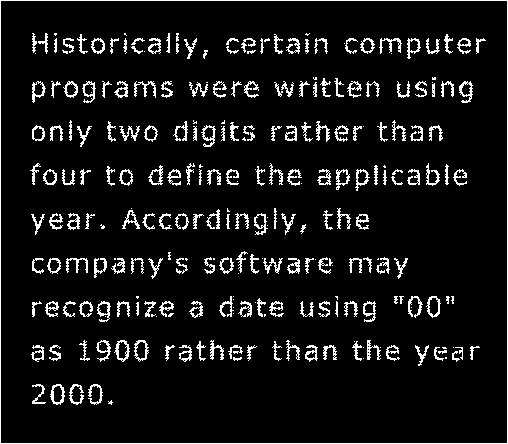


Variável 'img' (invertida e normalizada) definida com sucesso para as análises!


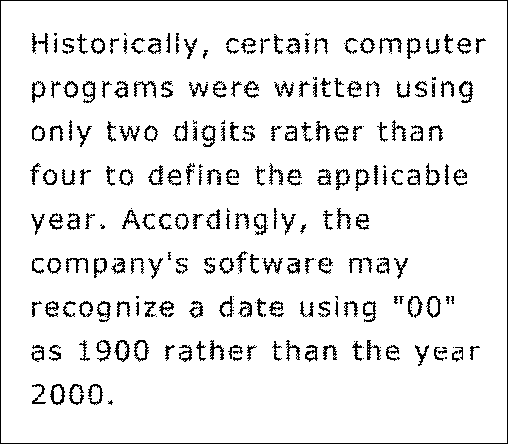

In [3]:
# URL oficial do repositório para baixar a imagem correta
url = "https://raw.githubusercontent.com/VielF/ColabProjects/main/dataset/OperacaoMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels).tif"
imagem_path = "Fig0907(a)(text_gaps_1_and_2_pixels).tif"

try:
    urllib.request.urlretrieve(url, imagem_path)
    print("Imagem baixada com sucesso!")
except Exception as e:
    print(f"Erro ao baixar a imagem: {e}")

# Carrega a imagem em escala de cinza
imagem_original = cv2.imread(imagem_path, 0)
if imagem_original is not None:
    print(f"Imagem original carregada. Dimensões: {imagem_original.shape}")
    cv2_imshow(imagem_original)

    # Inverte as cores da imagem para fundo branco e caracteres pretos
    imagem_invertida = 255 - imagem_original

    # Define a variável 'img' normalizada no intervalo [0, 1] que é utilizada no restante do notebook
    img = imagem_invertida.astype(np.float32) / 255.0
    print("\nVariável 'img' (invertida e normalizada) definida com sucesso para as análises!")
    cv2_imshow(imagem_invertida)
else:
    print("Erro: Não foi possível carregar a imagem baixada.")

**Justificativa da inversão da imagem:**

A imagem original possui fundo preto e caracteres brancos. Por isso, **invertemos suas intensidades**, obtendo fundo branco e caracteres pretos, uma representação mais comum no processamento de documentos. <br>
Essa alteração também é importante para a **aplicação de Otsu**, pois, na implementação utilizada, os pixels de menor intensidade são classificados como texto. Assim, com os caracteres em preto e o fundo em branco, a segmentação identifica diretamente os caracteres como a classe de **menor intensidade**. <br>
A inversão **não altera** a estrutura nem a posição dos caracteres e das falhas, apenas seus valores de intensidade.

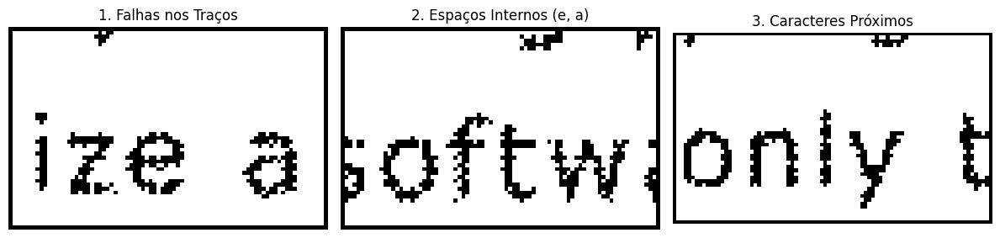

In [4]:
# Região com falhas nos traços
crop_falhas_coords = (130, 275, 80, 50)  # x, y, w, h

# Região com espaços internos
crop_internos_coords = (210, 230, 80, 50)

# Região com caracteres próximos
crop_proximos_coords = (30, 100, 85, 50)

# Extraindo os recortes
crop_falhas = img[crop_falhas_coords[1]:crop_falhas_coords[1]+crop_falhas_coords[3], crop_falhas_coords[0]:crop_falhas_coords[0]+crop_falhas_coords[2]]
crop_internos = img[crop_internos_coords[1]:crop_internos_coords[1]+crop_internos_coords[3], crop_internos_coords[0]:crop_internos_coords[0]+crop_internos_coords[2]]
crop_proximos = img[crop_proximos_coords[1]:crop_proximos_coords[1]+crop_proximos_coords[3], crop_proximos_coords[0]:crop_proximos_coords[0]+crop_proximos_coords[2]]

# Função auxiliar para adicionar uma borda preta
def adicionar_borda(imagem, espessura=1):
    return np.pad(imagem, pad_width=espessura, mode='constant', constant_values=0.0)

# Exibindo os recortes com bordas para validação visual
painel([
    adicionar_borda(crop_falhas),
    adicionar_borda(crop_internos),
    adicionar_borda(crop_proximos)
], [
    "1. Falhas nos Traços",
    "2. Espaços Internos (e, a)",
    "3. Caracteres Próximos"
], colunas=3, figsize=(12, 4))

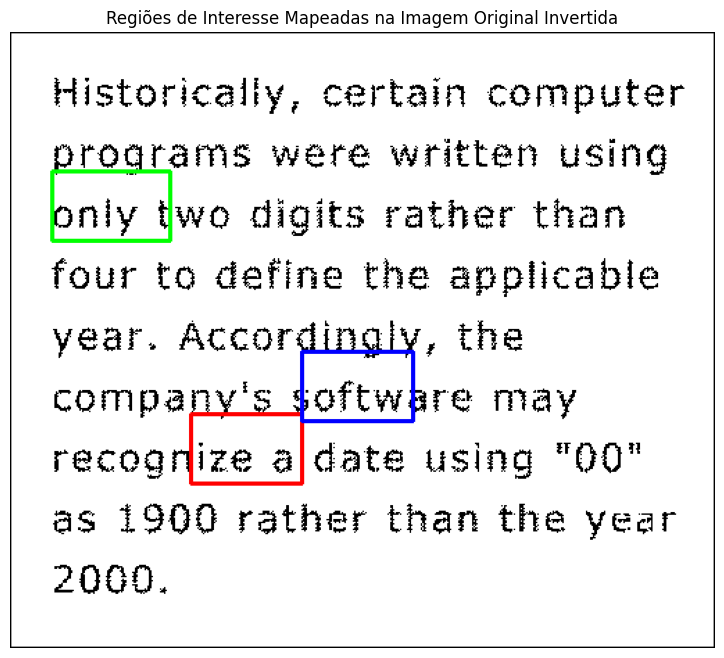

In [5]:
img_visualizacao = cv2.cvtColor((img * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)

# Definição de cores para cada marcação (BGR)
cor_falhas = (0, 0, 255)      # Vermelho
cor_internos = (255, 0, 0)    # Azul
cor_proximos = (0, 255, 0)    # Verde

# Desenha os retângulos das regiões mapeadas
# cv2.rectangle usa coordenadas (x1, y1) e (x2, y2)
cv2.rectangle(img_visualizacao,
              (crop_falhas_coords[0], crop_falhas_coords[1]),
              (crop_falhas_coords[0] + crop_falhas_coords[2], crop_falhas_coords[1] + crop_falhas_coords[3]),
              cor_falhas, 2)

cv2.rectangle(img_visualizacao,
              (crop_internos_coords[0], crop_internos_coords[1]),
              (crop_internos_coords[0] + crop_internos_coords[2], crop_internos_coords[1] + crop_internos_coords[3]),
              cor_internos, 2)

cv2.rectangle(img_visualizacao,
              (crop_proximos_coords[0], crop_proximos_coords[1]),
              (crop_proximos_coords[0] + crop_proximos_coords[2], crop_proximos_coords[1] + crop_proximos_coords[3]),
              cor_proximos, 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img_visualizacao, cv2.COLOR_BGR2RGB))
plt.title("Regiões de Interesse Mapeadas na Imagem Original Invertida")
plt.axis('off')
plt.show()

#### Análise e Finalidade dos Recortes Selecionados

Com o objetivo de analisar os impactos da filtragem e da segmentação nas estruturas da imagem, selecionamos três regiões representadas pelas marcações coloridas acima:

1. **Região de Falhas nos Traços (Borda Vermelha):**
   - **Objetivo:** Avaliar se o borramento natural provocado pelos filtros passa-baixa consegue atenuar ou fechar as descontinuidades indesejadas (lacunas de 1 e 2 pixels) nos traços das letras, restaurando a continuidade estrutural do texto após a binarização.

2. **Região com Espaços Internos Legítimos (Borda Azul):**
   - **Objetivo:** Monitorar o efeito colateral da filtragem passa-baixa. O espessamento dos traços não deve preencher completamente os vazios internos característicos de letras como "a", "e" e "o", que são cruciais para a legibilidade.

3. **Região com Caracteres Próximos (Borda Verde):**
   - **Objetivo:** Verificar se a suavização de altas frequências causa o espalhamento das bordas a ponto de unir artificialmente caracteres vizinhos muito próximos, o que causaria fusões indesejadas de texto nas máscaras finais.

### Filtragem passa-baixa no domínio da frequência

#### Relação entre o raio do filtro e a frequência de corte

Para embasar vocês, no exercício sobre filtragem na frequência (mais especificamente nas funções) o parâmetro `radius` representa a distância ao centro do espectro, medida em posições da matriz da FFT. Esse raio corresponde ao parâmetro $D_0$ das equações dos filtros. Após aplicar `fftshift`, a frequência zero fica na posição central. Quanto mais distante desse centro, maior a frequência espacial representada.

##### Imagens quadradas

Para uma imagem de tamanho $N \times N$, cada posição da FFT corresponde a um incremento de $1/N$ ciclos por pixel. Assim, a relação entre o raio e a frequência de corte é:

$$
f_c = \frac{D_0}{N}
\qquad\Longleftrightarrow\qquad
D_0 = f_c \cdot N
$$

Nessa expressão:

- $f_c$ é a frequência de corte, em ciclos por pixel;
- $D_0$ é o raio, em posições da matriz da FFT;
- $N$ é o número de linhas ou colunas da imagem quadrada utilizada na FFT.

Por exemplo, para uma imagem de $512 \times 512$ e um raio de 35:

$$
f_c = \frac{35}{512} \approx 0{,}0684 \text{ ciclos/pixel}
$$

Portanto, a configuração `radius=35` corresponde a uma frequência de corte de aproximadamente $0{,}0684$ ciclos por pixel nessa imagem.

| Raio $D_0$ | Frequência de corte $f_c$ | Período espacial $T=1/f_c$ |
|---:|---:|---:|
| 16 | 0,03125 ciclos/pixel | 32 pixels/ciclo |
| 35 | 0,06836 ciclos/pixel | 14,63 pixels/ciclo |
| 64 | 0,125 ciclos/pixel | 8 pixels/ciclo |

O período indica o tamanho de um ciclo de uma oscilação espacial. Sendo assim, ele não representa diretamente a espessura de uma letra ou a largura de uma falha, com isso, letras, bordas e falhas contêm várias frequências.

##### Imagens retangulares

Em uma imagem com $M$ linhas e $N$ colunas, os incrementos de frequência são:

$$
\Delta f_y = \frac{1}{M}
\qquad\text{e}\qquad
\Delta f_x = \frac{1}{N}
$$

Consequentemente, um círculo de raio $D_0$ na matriz da FFT corresponde aos seguintes cortes nos eixos:

$$
f_{c,x} = \frac{D_0}{N}
\qquad\text{e}\qquad
f_{c,y} = \frac{D_0}{M}
$$

Quando $M \neq N$, esses valores são diferentes. Portanto, um círculo definido diretamente pelas posições da matriz não representa a mesma frequência de corte em todas as direções. Para definir uma frequência de corte radial em ciclos por pixel, podemos normalizar cada eixo pelas respectivas dimensões:

$$
D_f(r,c) =
\sqrt{
\left(\frac{r-r_c}{M}\right)^2 +
\left(\frac{c-c_c}{N}\right)^2
}
$$

Aqui, $(r_c,c_c)$ é o centro da FFT deslocada. Como $D_f$ está em ciclos por pixel, ele deve ser comparado diretamente com $f_c$. Nesse caso, não é necessário converter o corte para um raio inteiro. Se houver preenchimento da imagem antes da FFT, devem ser utilizadas as dimensões da matriz após esse preenchimento.

### Como escolher a frequência de corte?

A conversão entre raio e frequência é matemática, mas a escolha do melhor corte depende do objetivo do processamento. Para caracteres com pequenas falhas, podemos testar, por exemplo:

$$
f_c \in \{0{,}06;\ 0{,}10;\ 0{,}16;\ 0{,}24\}
$$

Em um filtro passa-baixa:

- Cortes menores produzem maior suavização, podendo reduzir pequenas descontinuidades, mas também apagar traços finos ou unir letras próximas.
- Cortes maiores preservam mais detalhes, mas podem manter ruído e falhas.

A comparação deve utilizar os mesmos recortes da imagem, observando tanto a saída filtrada quanto a máscara obtida após Otsu ou k-means. Uma aproximação entre traços na imagem suavizada pode se transformar em conexão somente após a segmentação. Quando existe uma referência íntegra, IoU e Dice ajudam a avaliar as máscaras de região. Sem essa referência, a escolha deve ser justificada pela análise visual, considerando recuperação das falhas, preservação dos traços e separação entre caracteres. Com isso, não existe uma conversão direta entre “falha de 2 pixels” e um único raio ideal. O resultado também depende da espessura dos traços, da proximidade entre letras, do tipo de filtro e do método de segmentação.

### O significado do corte em cada filtro

No filtro ideal, $D_0$ define uma separação abrupta: as frequências dentro do raio são preservadas e as externas são anuladas. No Butterworth e no gaussiano, a atenuação é gradual. Nas fórmulas usuais deste exercício, em $D=D_0$:

$$
H_{\text{Butterworth}}(D_0)=0{,}5
$$

$$
H_{\text{Gaussiano}}(D_0)=e^{-1/2}\approx0{,}607
$$

Assim, usar o mesmo raio nos três filtros não produz exatamente a mesma suavização.

### Centro do filtro

O centro deve corresponder à frequência zero após `fftshift`, definida pelas dimensões da matriz:

$$
r_c = \left\lfloor \frac{M}{2} \right\rfloor,
\qquad
c_c = \left\lfloor \frac{N}{2} \right\rfloor
$$

Na função `createPB` do exercício, o argumento `center` utiliza a ordem coluna e linha: `center=(cols//2, rows//2)`. A posição do maior pico do espectro não deve ser usada como regra para definir esse centro.

Seja $D=\sqrt{f_x^2+f_y^2}$, em **ciclos/pixel**, e $f_c>0$:

$$H_I(D)=\begin{cases}1&D\leq f_c\\0&D>f_c\end{cases},\quad
H_B(D)=\frac{1}{1+(D/f_c)^{2n}},\quad
H_G(D)=e^{-D^2/(2f_c^2)}.$$

O resultado é $g=\Re\{\mathcal F^{-1}[H\mathcal F(f)]\}$. Usamos `fftshift` para centralizar o espectro e `ifftshift` antes da inversa. O preenchimento por reflexão reduz o contato artificial entre bordas opostas; o recorte devolve o tamanho original. Tenha atenção, pois $f_c$ é um parâmetro de escala; os três filtros não têm o mesmo ganho em $D=f_c$. Butterworth tem ganho 0,5 e gaussiano aproximadamente 0,607. Comparar o mesmo $f_c$ não significa igualar toda a resposta espectral. O ideal pode produzir oscilações (*ringing*); o gaussiano suaviza a transição; a ordem controla a transição do Butterworth. Valores menores de $f_c$ suavizam mais. A filtragem não reconstrói de forma garantida informação perdida: a união pode surgir somente após o limiar, com risco de deformar letras.

2. Implemente os filtros ideal, Butterworth e gaussiano no domínio da frequência. Teste pelo menos duas frequências de corte por filtro e compare as ordens 1, 2 e 4 do Butterworth. Apresente as respostas dos filtros, os espectros antes e depois da filtragem e as imagens resultantes. Nos recortes selecionados, observe se a suavização aproxima os traços interrompidos e se também provoca perda de detalhes ou aproximação indevida entre caracteres. Explique as etapas da função e registre os parâmetros utilizados. Não substitua a filtragem na frequência por um filtro espacial.

**Dica**: utilize as funções disponibilizadas no exercícios sobre filtragem na frequência.

In [6]:
def filtrar_frequencia(imagem, tipo='gaussiano', fc=0.1, n=2):

    M, N = imagem.shape
    #Preenchimento por reflexão para evitar vazamento de bordas (fringe effects)
    pad_r, pad_c = M // 2, N // 2
    img_pad = np.pad(imagem, ((pad_r, pad_r), (pad_c, pad_c)), mode='reflect')
    M_pad, N_pad = img_pad.shape

    #Transformada de Fourier 2D e centralização
    F = np.fft.fftshift(np.fft.fft2(img_pad))

    # Geração das coordenadas de frequência normalizadas
    u = np.arange(M_pad) - M_pad // 2
    v = np.arange(N_pad) - N_pad // 2
    V, U = np.meshgrid(v, u)

    # Distância
    D = np.sqrt((U / M_pad)**2 + (V / N_pad)**2)

    # Construção da função de transferência do filtro
    if tipo == 'ideal':
        H = np.where(D <= fc, 1.0, 0.0)
    elif tipo == 'butterworth':

        H = 1.0 / (1.0 + np.power(D / (fc + 1e-9), 2 * n))
    elif tipo == 'gaussiano':
        H = np.exp(- (D**2) / (2 * (fc**2)))
    else:
        raise ValueError("Tipo de filtro inválido. Escolha 'ideal', 'butterworth' ou 'gaussiano'.")

    # Filtragem no domínio da frequência
    G_shifted = F * H

    #Transformada Inversa e retorno ao domínio espacial
    g_pad = np.real(np.fft.ifft2(np.fft.ifftshift(G_shifted)))

    # Remove o preenchimento para recuperar o tamanho original da imagem
    g = g_pad[pad_r:pad_r + M, pad_c:pad_c + N]
    g = np.clip(g, 0.0, 1.0) # Garante intensidade válida

    return g, H, F, G_shifted

A função `filtrar_frequencia` foi adaptada da `createPB` para garantir maior precisão matemática e suavizar imperfeições espaciais:

- **Padding por Reflexão:** Substitui o preenchimento com zeros para suavizar transições nas bordas, eliminando artefatos artificiais de alta frequência.
- **FFT 2D e Centralização:** Aplica a Transformada de Fourier (`np.fft.fft2`) na imagem expandida e desloca a frequência zero para o centro (`np.fft.fftshift`).
- **Frequência Normalizada ($D$):** Em vez de usar raios em pixels, as coordenadas são normalizadas pelas dimensões da imagem com padding ($M_{pad}, N_{pad}$), medindo as distâncias diretamente em **ciclos por pixel**. Isso torna a frequência de corte $f_c$ independente do tamanho da imagem.
- **Filtragem e Inversa:** Multiplica o espectro pelo filtro ideal, Butterworth ou Gaussiano, aplica a inversa (`np.fft.ifft2`) e remove o padding para recuperar o tamanho original.
- **Tratamento de Ringing (`np.clip`):** Garante que os valores de intensidade permaneçam no intervalo real $[0, 1]$, limitando as ondulações espaciais (*ringing*) que ocorrem nas bordas de transições abruptas (como no filtro Ideal).

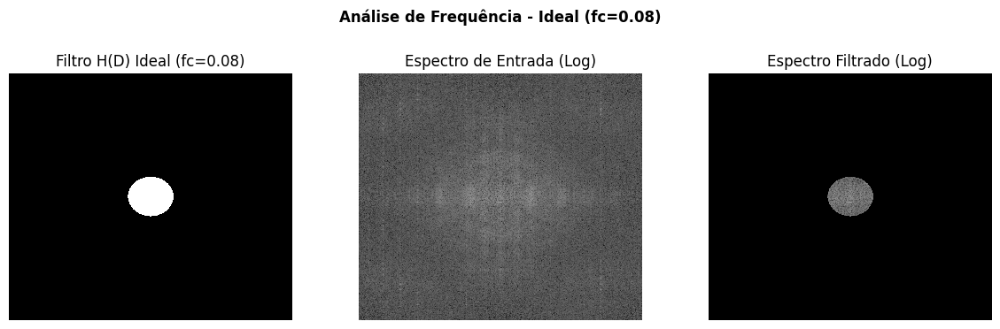

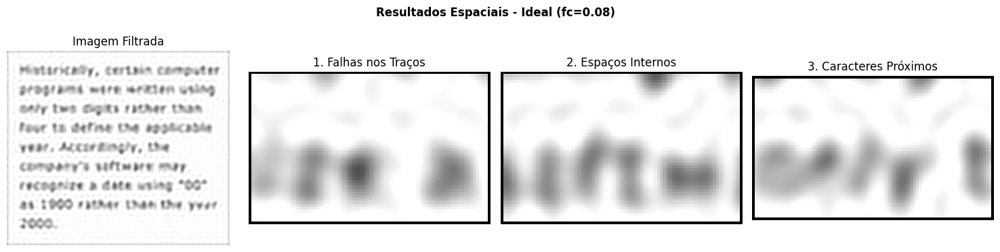

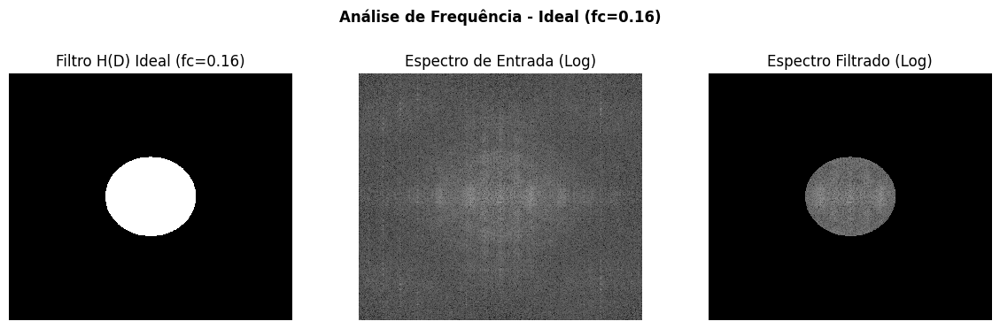

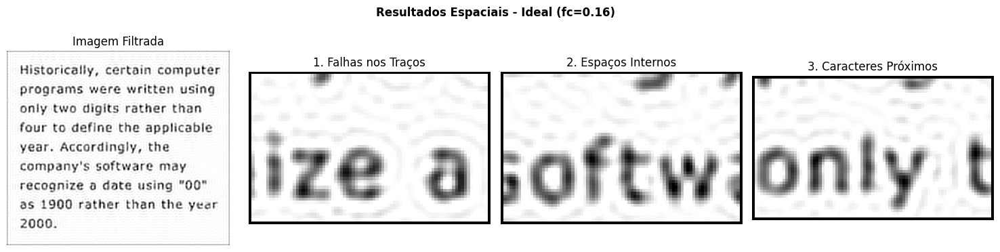

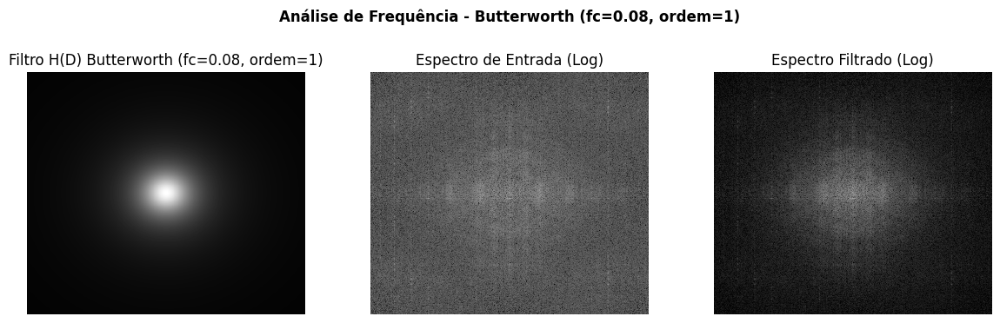

...

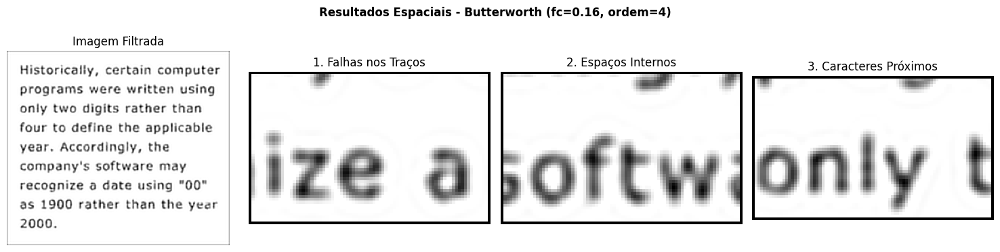

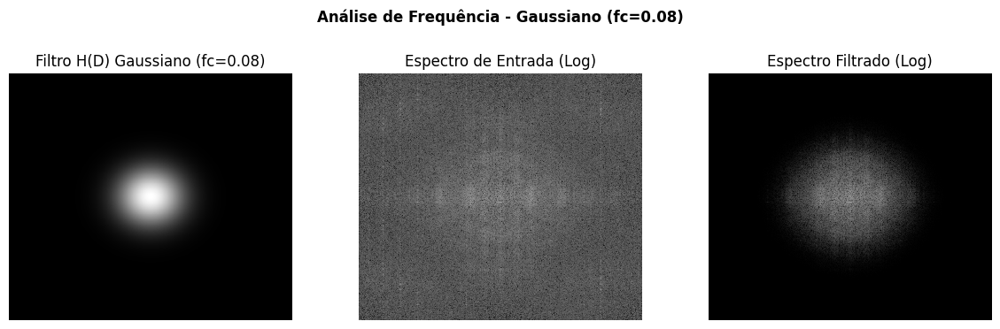

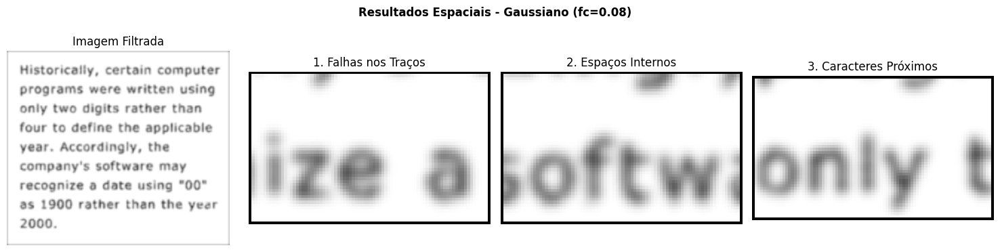

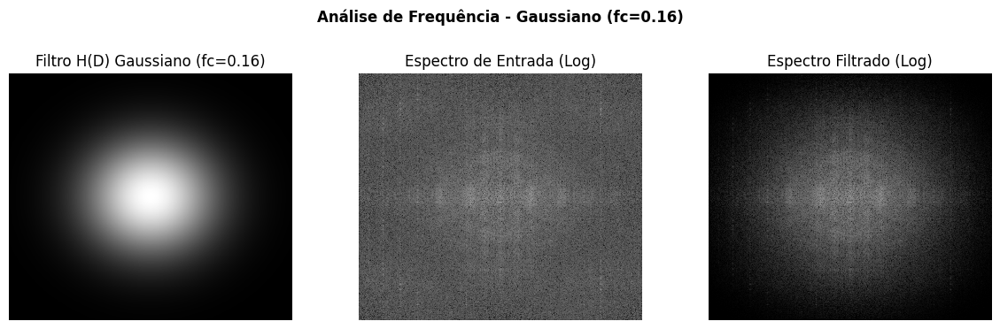

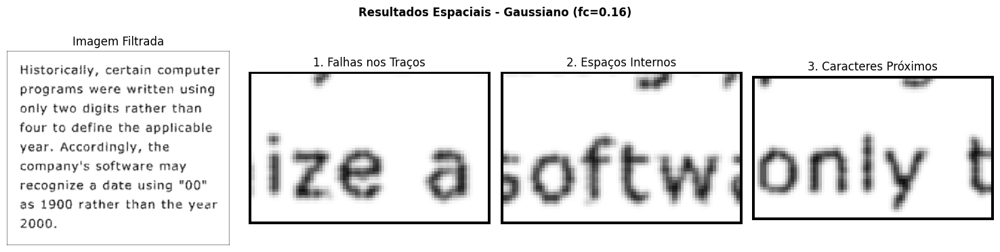

In [7]:
resultados_filtragem = {} # para armazenar todas as imagens filtradas

# Frequências de corte para teste
frequencias_corte = [0.08, 0.16]

for tipo in ['ideal', 'butterworth', 'gaussiano']:
    for fc in frequencias_corte:
        # Butterworth, ordens 1, 2 e 4
        ordens = [1, 2, 4] if tipo == 'butterworth' else [2]

        for n in ordens:
            # Filtrar imagem
            img_filtrada, H, F_original, F_filtrado = filtrar_frequencia(img, tipo=tipo, fc=fc, n=n)

            resultados_filtragem[(tipo, fc, n)] = img_filtrada # guarda a imagem filtrada

            # Espectros em escala logarítmica para visualização
            espectro_original = np.log(1 + np.abs(F_original))
            espectro_filtrado = np.log(1 + np.abs(F_filtrado))

            # Extraindo recortes da imagem resultante
            crop_f = img_filtrada[crop_falhas_coords[1]:crop_falhas_coords[1]+crop_falhas_coords[3],
                                 crop_falhas_coords[0]:crop_falhas_coords[0]+crop_falhas_coords[2]]
            crop_i = img_filtrada[crop_internos_coords[1]:crop_internos_coords[1]+crop_internos_coords[3],
                                 crop_internos_coords[0]:crop_internos_coords[0]+crop_internos_coords[2]]
            crop_p = img_filtrada[crop_proximos_coords[1]:crop_proximos_coords[1]+crop_proximos_coords[3],
                                 crop_proximos_coords[0]:crop_proximos_coords[0]+crop_proximos_coords[2]]

            # Título descritivo unificado
            label_filtro = f"{tipo.capitalize()} (fc={fc}" + (f", ordem={n})" if tipo == 'butterworth' else ")")

            # Resposta do Filtro e Espectros com título integrado na figura
            fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
            imagens_painel = [
                H,
                espectro_original / np.max(espectro_original),
                espectro_filtrado / (np.max(espectro_filtrado) + 1e-9)
            ]
            titulos_painel = [
                f"Filtro H(D) {label_filtro}",
                "Espectro de Entrada (Log)",
                "Espectro Filtrado (Log)"
            ]
            for ax, im, t in zip(axs, imagens_painel, titulos_painel):
                ax.imshow(im, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
                ax.set_title(t)
                ax.axis('off')
            fig.suptitle(f"Análise de Frequência - {label_filtro}", fontsize=12, fontweight='bold', y=1.05)
            fig.tight_layout()
            plt.show()

            # Imagem Completa e os Três Recortes de Referência com bordas para evitar mistura visual
            fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
            imagens_recortes = [
                img_filtrada,
                adicionar_borda(crop_f),
                adicionar_borda(crop_i),
                adicionar_borda(crop_p)
            ]
            titulos_recortes = [
                "Imagem Filtrada",
                "1. Falhas nos Traços",
                "2. Espaços Internos",
                "3. Caracteres Próximos"
            ]
            for ax, im, t in zip(axs, imagens_recortes, titulos_recortes):
                ax.imshow(im, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
                ax.set_title(t)
                ax.axis('off')
            fig.suptitle(f"Resultados Espaciais - {label_filtro}", fontsize=12, fontweight='bold', y=1.05)
            fig.tight_layout()
            plt.show()

##### Análise dos Recortes de Interesse

#### 1. Falhas nos Traços ("ize a")
- **Sem Filtro:** Descontinuidades nítidas de 1 a 2 pixels no texto.
- **Com $f_c = 0.16$:** Lacunas fechadas com sucesso. **Gaussiano** e **Butterworth (ordem 1)** entregam contornos mais fiéis e suaves. **Ideal** e **Butterworth (ordem 4)** mostram bordas serrilhadas (*ringing*).
- **Com $f_c = 0.08$:** Reconstrução excessiva; traços grossos deformam o "e" e o "a" e fundem letras.

#### 2. Espaços Internos ("softw")
- **Sem Filtro:** As aberturas internas (como o miolo do "o") estão limpas e preservadas.
- **Com $f_c = 0.16$:** Legibilidade mantida. O **Gaussiano** e o **Butterworth de ordem baixa** preservam melhor as cavidades legítimas.
- **Com $f_c = 0.08$:** Borramento excessivo fecha quase todas as aberturas internas em todos os filtros.

#### 3. Caracteres Próximos ("only t")
- **Sem Filtro:** Separação geométrica correta entre letras vizinhas.
- **Com $f_c = 0.16$:** Caracteres permanecem bem separados. O **Filtro Gaussiano** apresenta a melhor preservação de espaçamento.
- **Com $f_c = 0.08$:** Fusão completa de letras vizinhas em blocos escuros contínuos em todos os filtros.

##### Análise das frequências de corte e comportamento dos filtros

**Parâmetros de base:**
- Frequências de corte testadas ($f_c$): **0.08** e **0.16**.
  - Justificativa das escolhas: Esses valores foram selecionados com base no intervalo sugerido pelo enunciado ($0{,}06$ a $0{,}24$), representando um cenário de suavização moderada ($f_c=0.16$) e outro de suavização mais intensa ($f_c=0.08$) para avaliar os limites de reconstrução dos traços e degradação dos caracteres.
- Filtros aplicados: **Ideal**, **Butterworth** (ordens 1, 2 e 4) e **Gaussiano**.

<br>

**Explicação da Frequência de Corte ($f_c$):**
A frequência de corte define o limite do borramento da imagem. Em vez de usarmos o raio ($D_0$) direto nas posições da matriz, usamos o $f_c$ (em ciclos por pixel), o que ajuda a padronizar o corte não importando o tamanho da imagem (já que $D_0 = f_c \cdot N$).

- **Cortes menores (ex: fc = 0.08):** Borram bem mais a imagem. São ótimos para juntar grandes espaços vazios e fechar os cortes das letras, mas o problema é que acabam apagando traços finos e colando caracteres que estão muito próximos.
- **Cortes maiores (ex: fc = 0.16):** Preservam melhor os detalhes, os buracos internos (como do "e" e do "a") e o formato original das letras. O lado ruim é que, se a imagem estiver com muitas falhas grandes, esse corte pode não dar conta de fechar todas elas.

<br>

**O comportamento de cada filtro com o corte:**

Abaixo, comparamos como cada filtro reage à mesma frequência de corte. Vale destacar que aplicar o mesmo $f_c$ não suaviza a imagem de forma idêntica em todos eles, pois a curva de transição de cada filtro age de maneira muito particular

- **Filtro Ideal:** Faz um corte muito seco e direto. Tudo o que está dentro do raio ($f_c$) passa; o que está fora é zerado na hora.
  - **O problema:** Esse corte reto gera aquelas ondinhas na imagem conhecidas como *ringing* (pequenos pontos ou linhas falsas que aparecem perto das bordas). Ele fecha bem as falhas, mas suja as margens e os contornos das letras.
- **Filtro Butterworth:** Faz uma suavização mais contínua, e a curva dele é controlada pela "ordem" ($n$). Nele, bem no ponto de corte ($f_c$), o valor cai pela metade (0,5).
  - **Ordem 1:** A transição é bem lenta e suave. O visual fica muito parecido com o do filtro Gaussiano, sem criar ondas falsas.
  - **Ordem 2:** Funciona como um meio-termo. Engrossa os traços de um jeito mais equilibrado.
  - **Ordem 4:** Como o corte aqui já é mais forte e reto, o resultado fica bem parecido com o filtro Ideal. Começa a juntar partes pequenas das letras (como colar letras vizinhas no fc=0.08) e já mostra um pouco de *ringing*.
- **Filtro Gaussiano:** Tem a transição mais suave e natural de todas. No ponto de corte ($f_c$), o valor dele cai para mais ou menos 0,607.
  - **A vantagem:** Como o corte dele não é seco, ele nunca cria aquele efeito de *ringing*. Ele borra a imagem de um jeito mais natural, engrossa os traços só o necessário e mantém as letras separadas bem melhor que os outros.

<br>

**Conclusão sobre as frequências e os filtros:**

Não existe uma fórmula matemática perfeita que diga "para uma falha de 2 pixels, use o raio X". Tudo depende da grossura original dos traços e de quão perto as letras estão umas das outras.

A escolha ideal é sempre um meio-termo visual: precisamos de um corte pequeno o suficiente para espalhar a cor e tapar os buracos do texto, mas grande o suficiente para não preencher os espaços internos do "a" e do "e", nem transformar duas letras numa mancha preta só. Pelos nossos testes, filtros com uma suavização mais natural (Gaussiano e Butterworth de ordem baixa) lidam bem melhor com isso do que os de corte muito seco (Ideal).

### Otsu, Canny e k-means

3. Aplique Otsu, k-means e Canny à imagem sem filtragem e a cada versão filtrada. Apresente os resultados lado a lado, utilizando os mesmos recortes e a mesma escala de exibição. Realize duas comparações:

- Entre métodos: para uma mesma imagem de entrada, compare Otsu, k-means e Canny.
- Antes e depois da filtragem: para um mesmo método, compare a entrada sem filtro com as versões filtradas.

Para Otsu e k-means, analise as máscaras de região: as falhas foram reduzidas? Os traços e espaços internos foram preservados? Houve união entre caracteres?

Para Canny, analise os mapas de bordas: aparecem contornos adicionais ao redor das falhas? Esses contornos diminuem após a filtragem? As bordas externas dos caracteres continuam bem definidas?

Canny produz bordas, enquanto Otsu e k-means produzem regiões. Portanto, a ausência de uma borda em uma falha não demonstra, por si só, que a região foi corretamente recuperada. Mantenha fixos os parâmetros do Canny e a configuração do k-means na comparação inicial, registrando-os. O limiar de Otsu será recalculado para cada entrada, pois faz parte do próprio método.

#### Funções utilizadas na questão 3 (Otsu, K-means e Canny)

##### Otsu

In [8]:
# Otsu
def otsu_threshold(image):
    '''
    Calcula o limiar de Otsu pela maior variância entre as classes.
    '''

    image = image.astype(np.uint8)
    hist = np.bincount(image.ravel(), minlength=256) # quantos pixels há em cada nível de cinza
    prob = hist / image.size

    cumulative_prob = np.cumsum(prob)
    cumulative_mean = np.cumsum(prob * np.arange(256))
    global_mean = cumulative_mean[-1]

    numerator = (global_mean * cumulative_prob - cumulative_mean) ** 2
    denominator = cumulative_prob * (1 - cumulative_prob)
    denominator = np.where(denominator == 0, 1e-10, denominator)

    sigma_b2 = numerator / denominator

    return int(np.argmax(sigma_b2))

# marca os pixels ≥ limiar como 255 (classe clara) e os demais como 0
def aplicar_otsu(image, threshold):
    return (image >= threshold).astype(np.uint8) * 255


O **Otsu** calcula automaticamente um limiar de intensidade para separar o texto do fundo, escolhendo o valor que melhor distingue os dois grupos de pixels (maior variância entre as classes). A função aplicar_otsu usa esse limiar para gerar a máscara binária. Como o nosso texto é escuro, aplicamos o limiar de modo que os pixels ≤ limiar formam o texto.

##### K-means

In [9]:
# K-means
def kmeans_segmentation(image, k=2, max_iter=100, tol=1e-4, random_state=None):
    '''
    A função sorteia k centroides, atribui cada pixel ao mais próximo e recalcula até convergir.
    '''

    rng = np.random.default_rng(random_state) # gerador com semente fixa

    if image.ndim == 2:
        pixels = image.reshape(-1, 1).astype(np.float64)
        original_shape = image.shape
        channels = 1
    else:
        h, w, c = image.shape
        pixels = image.reshape(-1, c).astype(np.float64)
        original_shape = (h, w)
        channels = c

    n_pixels = pixels.shape[0]
    indices = rng.choice(n_pixels, size=k, replace=False)
    centroids = pixels[indices].copy()

    labels = np.zeros(n_pixels, dtype=np.int32)

    for _ in range(max_iter):
        # atribuição
        distances = np.sqrt(((pixels[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
        new_labels = np.argmin(distances, axis=1) # índice do centroide mais próximo de cada pixel

        # atualização
        new_centroids = centroids.copy()
        for cluster in range(k):
            cluster_pixels = pixels[new_labels == cluster]
            if len(cluster_pixels) > 0:
                new_centroids[cluster] = cluster_pixels.mean(axis=0)
            else:
                new_centroids[cluster] = pixels[rng.integers(0, n_pixels)]

        # critério de convergência
        shift = np.linalg.norm(new_centroids - centroids) # deslocamento total dos centroides
        labels = new_labels
        centroids = new_centroids

        if shift < tol:
            break

    segmented = centroids[labels]

    if channels == 1:
        segmented = segmented.reshape(original_shape)
    else:
        segmented = segmented.reshape(*original_shape, channels)

    return segmented.astype(image.dtype), labels.reshape(original_shape), centroids


O **K-means** agrupa os pixels em k grupos de intensidade parecida. Usamos o k=2, que separa o texto do fundo. A função sorteia dois centroides, atribui cada pixel ao centroide mais próximo e recalcula os centroides até eles pararem de mudar.

##### Canny

In [10]:
# Canny

# convolução
def convolve2d(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(image, ((ph, ph), (pw, pw)), mode='constant') # adiciona padding
    out = np.zeros((h, w), dtype=float)

    for i in range(h):
        for j in range(w):
            out[i, j] = np.sum(padded[i:i+kh, j:j+kw] * kernel)
    return out

# kernel gaussiano
def gaussian_kernel(size=5, sigma=1.0):
    ax = np.arange(-(size // 2), size // 2 + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2)/(2*sigma**2))
    return kernel / np.sum(kernel)

# filtro de sobel
def sobel_filters(image):
    Kx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
    Ky = np.array([[1,2,1],[0,0,0],[-1,-2,-1]])
    Gx = convolve2d(image, Kx)
    Gy = convolve2d(image, Ky)
    magnitude = np.hypot(Gx, Gy) # magnitude é √(Gx² + Gy²)
    magnitude = magnitude / (magnitude.max() + 1e-10) * 255
    direction = np.arctan2(Gy, Gx) # direção do gradiente (perpendicular à borda), em radianos
    return magnitude, direction

# mantém só os pixels que são máximos locais da magnitude na direção do gradiente
def non_max_suppression(magnitude, direction):
    h, w = magnitude.shape
    out = np.zeros((h, w), dtype=np.float32)
    angle = np.degrees(direction) # converte a matriz inteira de radianos para graus
    angle[angle < 0] += 180

    for i in range(1, h-1):
        for j in range(1, w-1):
            q = r = 0
            a = angle[i, j]

            if (0 <= a < 22.5) or (157.5 <= a <= 180):
                q, r = magnitude[i, j+1], magnitude[i, j-1]
            elif 22.5 <= a < 67.5:
                q, r = magnitude[i+1, j-1], magnitude[i-1, j+1]
            elif 67.5 <= a < 112.5:
                q, r = magnitude[i+1, j], magnitude[i-1, j]
            else:
                q, r = magnitude[i-1, j-1], magnitude[i+1, j+1]

            if magnitude[i, j] >= q and magnitude[i, j] >= r:
                out[i, j] = magnitude[i, j]
    return out

# separa as bordas
def double_threshold(image, T1=30, T2=100):
    weak, strong = 75, 255
    result = np.zeros(image.shape, dtype=np.uint8)
    result[image >= T2] = strong
    result[(image >= T1) & (image < T2)] = weak
    return result, weak, strong

# mantém um pixel fraco só se algum dos 8 vizinhos for forte
def hysteresis(image, weak=75, strong=255):
    h, w = image.shape
    out = image.copy()
    for i in range(1, h-1):
        for j in range(1, w-1):
            if out[i, j] == weak:
                if np.any(out[i-1:i+2, j-1:j+2] == strong): # ve se há algum vizinho forte na vizinhança
                    out[i, j] = strong
                else:
                    out[i, j] = 0
    return out

def canny(image, sigma=1.0, T1=10, T2=23):
    '''
    A função faz em ordem a suavização gaussiana, Sobel, supressão de não-máximos, limiar duplo e histerese.
    '''

    smoothed = convolve2d(image, gaussian_kernel(5, sigma))
    magnitude, direction = sobel_filters(smoothed)
    nms = non_max_suppression(magnitude, direction)
    # print("\nnms.max: ", nms.max()) # para testes
    thresh, weak, strong = double_threshold(nms, T1, T2)

    return hysteresis(thresh, weak, strong)


O **Canny** detecta as bordas da imagem em cinco etapas:
- Suavização gaussiana (reduz ruído);
- Filtro de Sobel (calcula a intensidade e a direção da mudança de brilho);
- Supressão de não-máximos (afina as bordas);
- Limiar duplo (separa bordas fortes e fracas);
- Histerese (mantém as fracas só se tocarem uma forte).

#### Resultados das imagens na questão 3

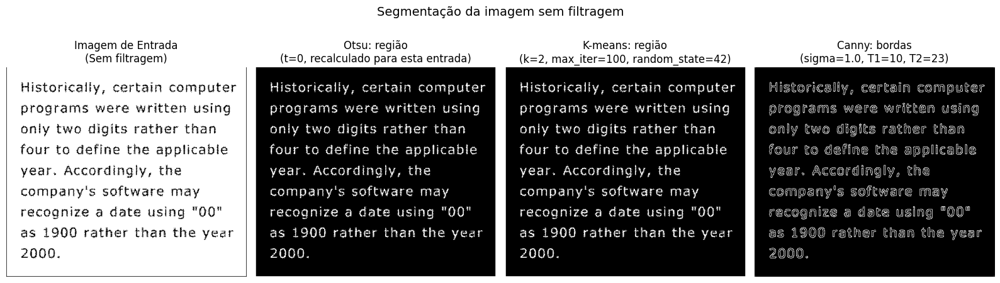

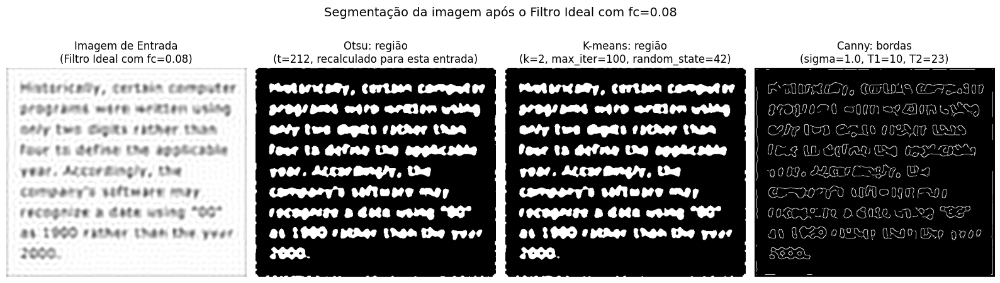

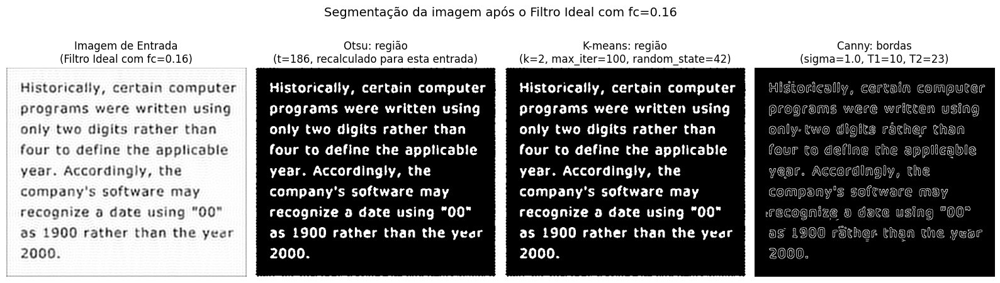

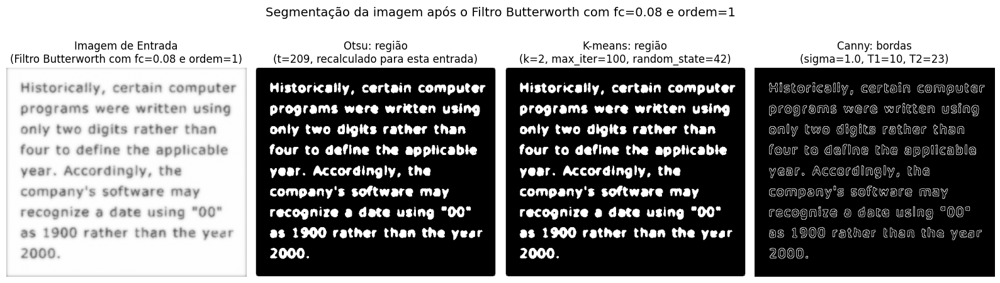

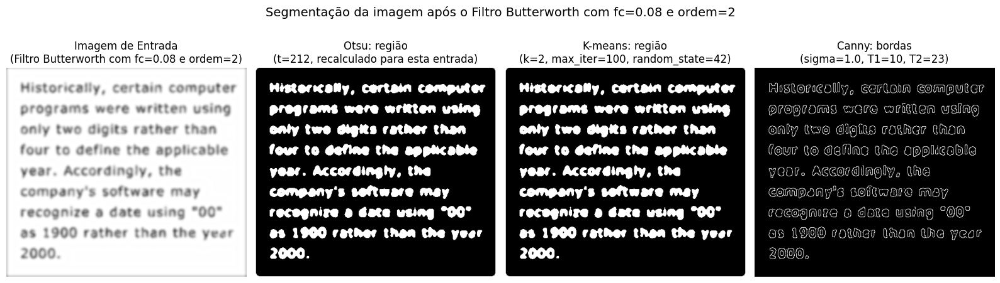

...

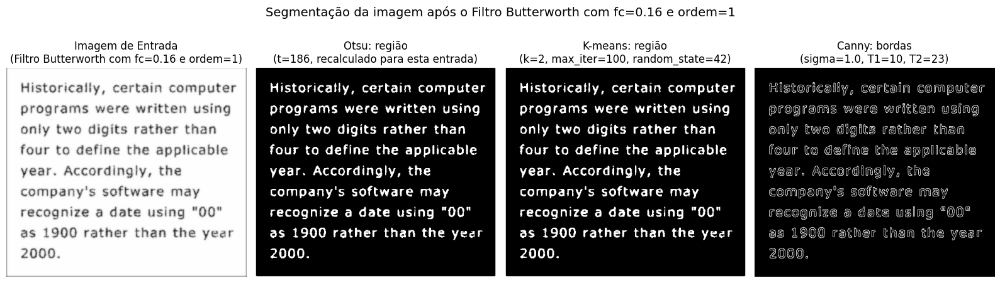

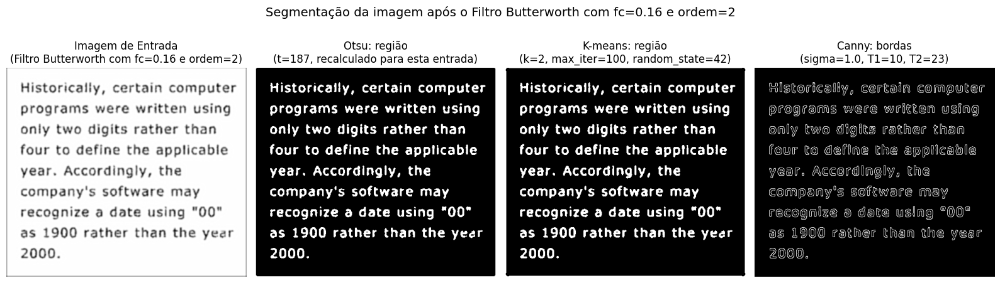

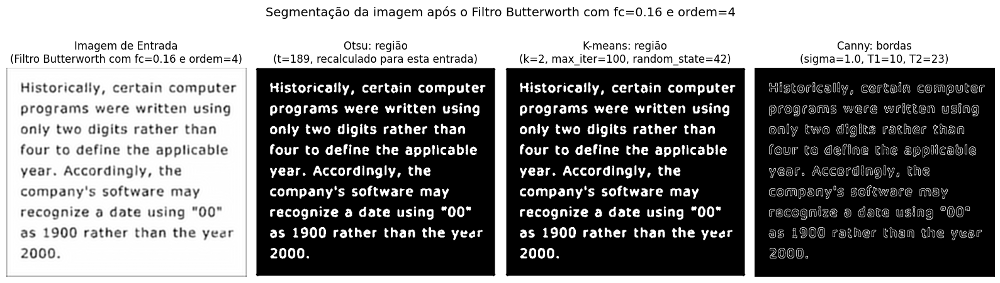

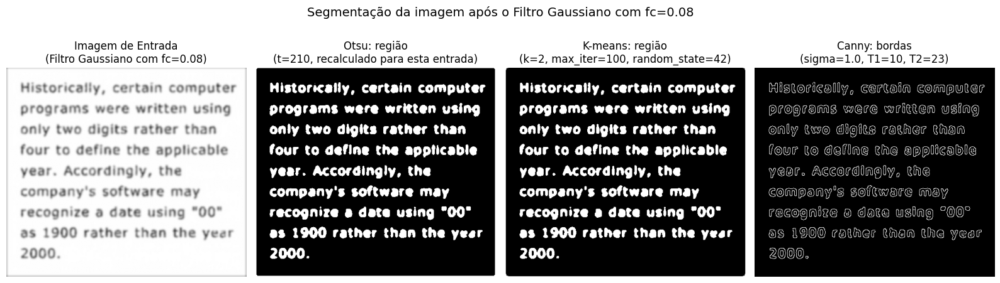

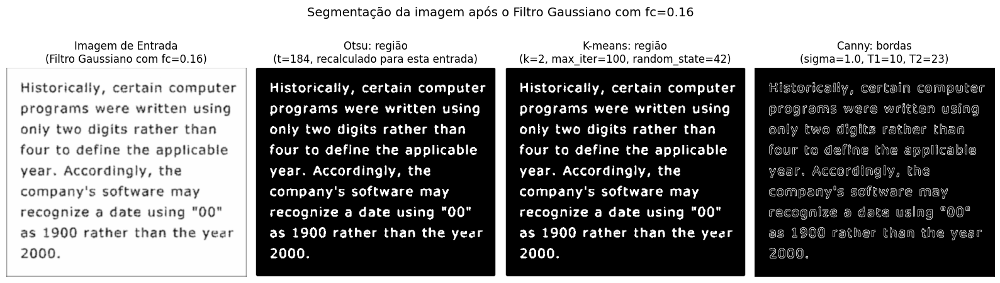

In [11]:
# Parâmetros fixos da questão 3
K_KMEANS = 2
MAX_ITER_KMEANS = 100
SEMENTE_KMEANS = 42
SIGMA_CANNY = 1.0
T1_CANNY = 10
T2_CANNY = 23

# aplica Otsu, k-means e Canny a imagem
def segmentar_imagem(imagem):
    entrada = (imagem * 255).astype(np.uint8)

    # otsu
    limiar = otsu_threshold(entrada)
    otsu = aplicar_otsu(255 - entrada, 255 - limiar) # a inversão permite aplicar o limiar à classe escura da imagem original

    _, labels, centroids = kmeans_segmentation(entrada, k=K_KMEANS, max_iter=MAX_ITER_KMEANS, random_state=SEMENTE_KMEANS) # k-means

    indice_texto = 0 # texto é o cluster de centroide mais escuro
    for c in range(1, K_KMEANS):
        if centroids[c] < centroids[indice_texto]:
            indice_texto = c

    altura, largura = entrada.shape
    kmeans = np.zeros((altura, largura), dtype=np.uint8)
    for i in range(altura):
        for j in range(largura):
            if labels[i, j] == indice_texto:
                kmeans[i, j] = 255

    var_canny = canny(entrada, sigma=SIGMA_CANNY, T1=T1_CANNY, T2=T2_CANNY) # canny

    return {"entrada": entrada, "otsu": otsu, "limiar": limiar, "kmeans": kmeans, "canny": var_canny}


# mostra a imagem de entrada e os resultados de Otsu, k-means e Canny lado a lado
def comparar_segmentacao(imagem, titulo):
    resposta = segmentar_imagem(imagem)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))

    axes[0].imshow(resposta["entrada"], cmap='gray', vmin=0, vmax=255)
    axes[0].set_title(f"Imagem de Entrada\n({titulo})")

    axes[1].imshow(resposta["otsu"], cmap='gray', vmin=0, vmax=255)
    axes[1].set_title(f"Otsu: região\n(t={resposta['limiar']}, recalculado para esta entrada)")

    axes[2].imshow(resposta["kmeans"], cmap='gray', vmin=0, vmax=255)
    axes[2].set_title(f"K-means: região\n(k={K_KMEANS}, max_iter={MAX_ITER_KMEANS}, random_state={SEMENTE_KMEANS})")

    axes[3].imshow(resposta["canny"], cmap='gray', vmin=0, vmax=255)
    axes[3].set_title(f"Canny: bordas\n(sigma={SIGMA_CANNY}, T1={T1_CANNY}, T2={T2_CANNY})")

    for ax in axes:
        ax.axis("off")

    if titulo == "Sem filtragem":
        descricao = "sem filtragem"
    else:
        descricao = f"após o {titulo}"

    fig.suptitle(f"Segmentação da imagem {descricao}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

    return resposta


segmentacoes = {} # imagens segmentadas

segmentacoes["Sem filtragem"] = comparar_segmentacao(img, "Sem filtragem")

for (tipo, fc, n), imagem_filtrada in resultados_filtragem.items():
    titulo = f"Filtro {tipo.capitalize()} com fc={fc}"
    if tipo == 'butterworth':
        titulo += f" e ordem={n}"

    segmentacoes[titulo] = comparar_segmentacao(imagem_filtrada, titulo)

##### Aplicação nos Recortes

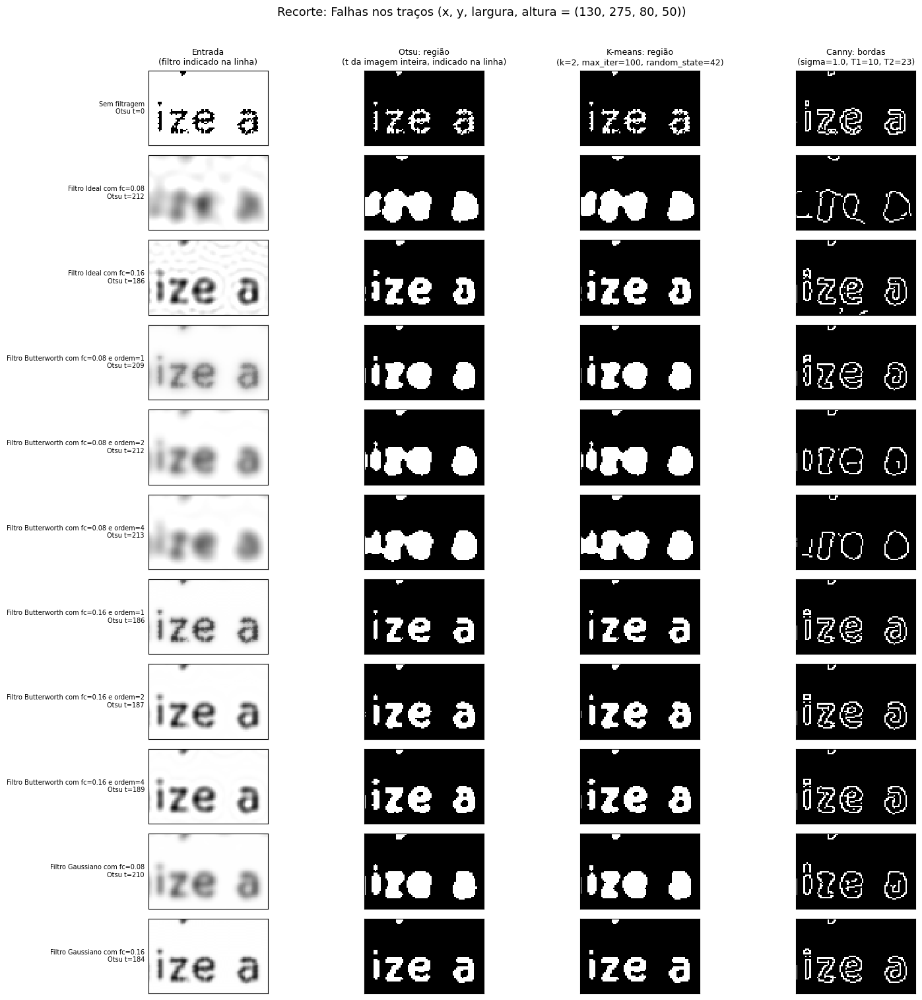

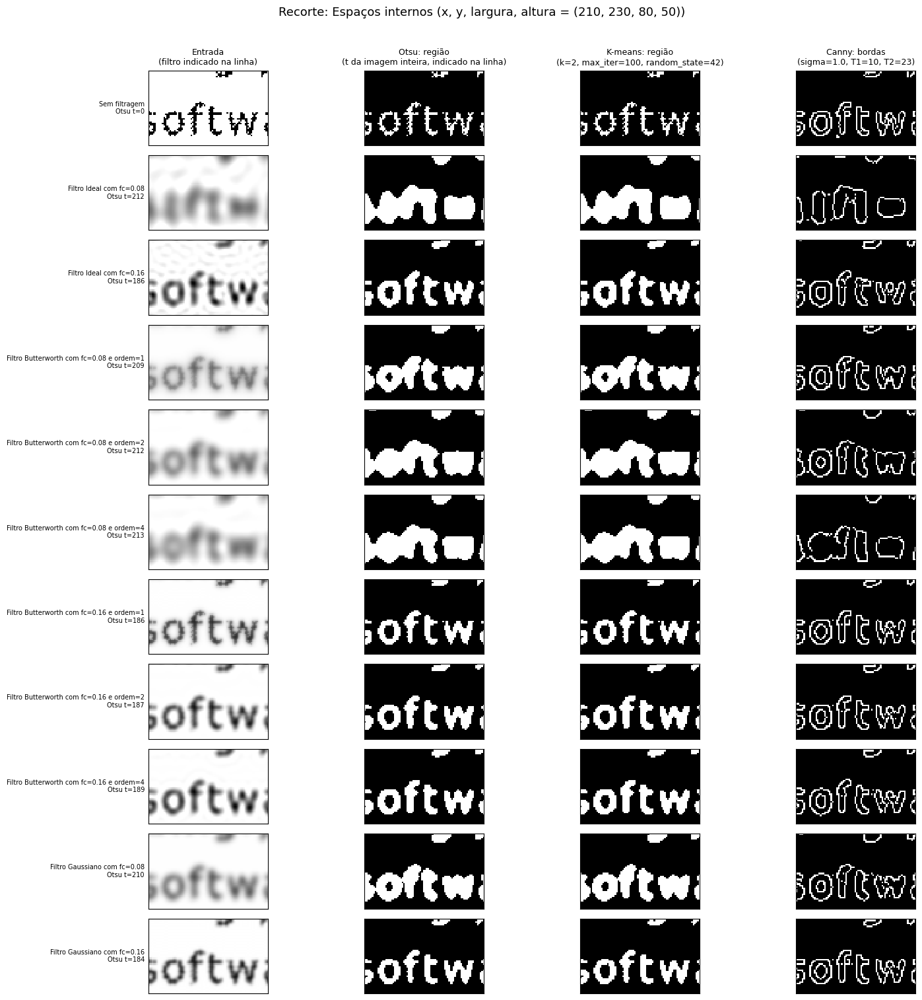

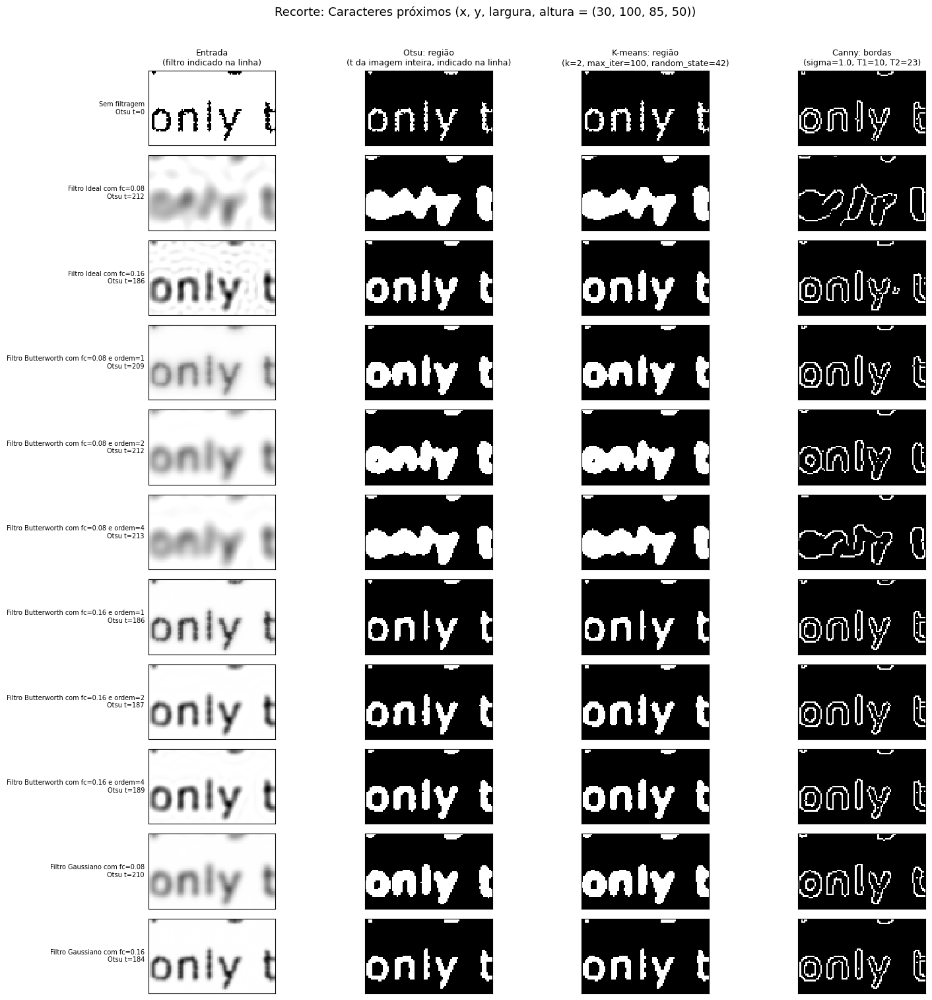

In [12]:
recortes = {"Falhas nos traços": crop_falhas_coords, "Espaços internos": crop_internos_coords, "Caracteres próximos": crop_proximos_coords}

# recorta a imagem
def extrair_recorte(imagem, coordenadas):
    x, y, largura, altura = coordenadas
    return imagem[y:y+altura, x:x+largura]

# mostra para um recorte (entrada, Otsu, k-means e Canny) recortados da segmentação da imagem inteira
def comparar_recorte(nome, coords):
    titulos = list(segmentacoes.keys())
    colunas = [("entrada", "Entrada\n(filtro indicado na linha)"),
               ("otsu", "Otsu: região\n(t da imagem inteira, indicado na linha)"),
               ("kmeans", f"K-means: região\n(k={K_KMEANS}, max_iter={MAX_ITER_KMEANS}, random_state={SEMENTE_KMEANS})"),
               ("canny", f"Canny: bordas\n(sigma={SIGMA_CANNY}, T1={T1_CANNY}, T2={T2_CANNY})")]

    fig, axes = plt.subplots(len(titulos), 4, figsize=(16, 1.4 * len(titulos)))

    for r, titulo in enumerate(titulos):
        for c, (chave, rotulo) in enumerate(colunas):

            mapa = extrair_recorte(segmentacoes[titulo][chave], coords)
            axes[r, c].imshow(mapa, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])

            if r == 0:
                axes[r, c].set_title(rotulo, fontsize=9)

        limiar = segmentacoes[titulo]["limiar"]
        axes[r, 0].set_ylabel(f"{titulo}\nOtsu t={limiar}", rotation=0, ha='right', va='center', fontsize=7)

    fig.suptitle(f"Recorte: {nome} (x, y, largura, altura = {coords})", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

for nome, coords in recortes.items():
    comparar_recorte(nome, coords)

#### Análise visual dos resultados da questão 3

Para comparar o **Otsu** com o **k-means**, o código abaixo conta em quantos pixels as duas máscaras são diferentes. Usamos isso **só para mostrar o quanto os dois métodos se parecem**, e por isso escrevemos **uma análise só para os dois**.

In [13]:
# colocado só para reforçar que o Otsu e o k-means são bem parecidos

print("Diferença de pixels:\n")

for titulo, res in segmentacoes.items():
    h, w = res["otsu"].shape
    dif = 0
    for i in range(h):
        for j in range(w):
            if res["otsu"][i, j] != res["kmeans"][i, j]:
                dif += 1
    porcentagem = dif / (h * w) * 100
    print(f"{titulo}: Otsu x K-means diferem em {dif} pixels ({porcentagem:.2f}% da imagem)")

Diferença de pixels:

Sem filtragem: Otsu x K-means diferem em 0 pixels (0.00% da imagem)
Filtro Ideal com fc=0.08: Otsu x K-means diferem em 972 pixels (0.43% da imagem)
Filtro Ideal com fc=0.16: Otsu x K-means diferem em 0 pixels (0.00% da imagem)
Filtro Butterworth com fc=0.08 e ordem=1: Otsu x K-means diferem em 0 pixels (0.00% da imagem)
Filtro Butterworth com fc=0.08 e ordem=2: Otsu x K-means diferem em 0 pixels (0.00% da imagem)
Filtro Butterworth com fc=0.08 e ordem=4: Otsu x K-means diferem em 2401 pixels (1.06% da imagem)
Filtro Butterworth com fc=0.16 e ordem=1: Otsu x K-means diferem em 0 pixels (0.00% da imagem)
Filtro Butterworth com fc=0.16 e ordem=2: Otsu x K-means diferem em 2806 pixels (1.24% da imagem)
Filtro Butterworth com fc=0.16 e ordem=4: Otsu x K-means diferem em 0 pixels (0.00% da imagem)
Filtro Gaussiano com fc=0.08: Otsu x K-means diferem em 2891 pixels (1.28% da imagem)
Filtro Gaussiano com fc=0.16: Otsu x K-means diferem em 0 pixels (0.00% da imagem)


**Parâmetros fixos**:
- O limiar de **Otsu** é recalculado para cada entrada.
- **K-means**: k=2, max_iter=100, random_state=42.
- **Canny**: sigma=1.0, T1=10, T2=23.

<br>

**Explicação dos parâmetros escolhidos:**
- **K-means**:
  - Usamos **k=2** para separar só o texto e o fundo.
  - O **max_iter=100** é o limite de repetições, e o algoritmo para antes se os centroides pararem de mudar.
  - O **random_state=42** deixa o resultado sempre igual a cada execução.
- **Canny**:
  - O **sigma=1.0** suaviza a imagem antes de achar as bordas.
  - Os limiares foram escolhidos testando e são iguais para todas as imagens. Com T2=100 ou 120, as imagens com fc=0.08 ficaram sem nenhum contorno, porque o maior valor de borda delas ficou entre 68,9 e 87 (medido nos testes com nms.max() na função de canny), abaixo de T2.
    - Baixar o T2 trouxe contornos para todas as imagens e deixou as letras mais contínuas.
    - Mudar o T1 quase não fez diferença.
    - Ficamos com **T2=23** e **T1=10**, e o T1 fica entre um terço e metade do T2, como é o costume. O lado ruim de baixar o T2 é que aparecem alguns contornos que não deveriam existir, como no filtro ideal com fc=0.16.

<br>

**Análise entre métodos:**

Aqui comparamos os três métodos na mesma imagem de entrada. O Otsu e o k-means pintam as letras por inteiro, em branco sobre fundo preto. O Canny mostra só o contorno das letras, com uma linha por fora e outra por dentro de cada traço.

- **Sem filtragem**: as máscaras do Otsu e do k-means mostram as falhas direto, como buracos e cortes nos traços. O Canny esconde parte delas, porque os contornos saem quase contínuos. Isso não quer dizer que as falhas sumiram. Elas continuam na imagem, e o Canny só as suaviza porque já borra a imagem antes de achar as bordas.
- **Com fc=0.16**: os três métodos concordam. As máscaras mostram letras cheias, sem falhas nos traços, e o Canny mostra contornos contínuos. Os defeitos são parecidos, com bordas irregulares nas máscaras e contornos que não deveriam existir no Canny, como visto no filtro ideal.
- **Com fc=0.08**: as máscaras mostram letras muito grossas e, nos piores filtros, coladas. O Canny acompanha essas formas, então quando as letras colam os contornos também colam ou se perdem. Nos piores casos (Ideal e Butterworth de ordem 4) o Canny deixa de mostrar letras.
- **Otsu e k-means entre si**: dão quase o mesmo resultado. Em 7 das 11 entradas as máscaras são iguais e, nas outras 4, diferem em no máximo 1.28% da imagem, o que não se vê nas figuras. Os dois separam os pixels em texto e fundo e os pontos de corte ficam quase iguais, então só mudam de grupo alguns pixels da borda das letras. Não há um padrão claro por filtro (3 das 5 entradas com fc=0.08 e 1 das 5 com fc=0.16). Na imagem sem filtro a diferença é zero, porque só existem os valores 0 e 255.

O **Canny** só mostra contornos, então a falta de borda em uma falha não prova que ela foi corrigida.

<br>

**Otsu antes e depois da filtragem:**

- **Sem filtragem (t=0)**: as letras têm falhas, com traços pontilhados e cortados, mas os espaços internos e a separação entre as letras estão preservados. As aspas duplas de "00" ficam separadas.
  - **Explicação do t=0**: O título mostra t=0 porque a imagem só tem os valores 0 (texto) e 255 (fundo), então qualquer limiar de 0 a 254 dá a mesma máscara. A função do professor devolve o primeiro valor, que é 0. Na nossa versão anterior de teste, que usava o meio do intervalo, o limiar seria 127. Mantivemos a função do professor sem mudar. A máscara marca os pixels menores ou iguais a t, então com t=0 ela marca os pixels de valor 0, que são o texto.
- Com **fc=0.16**, em todos os filtros, as falhas fecham e as letras ficam legíveis e separadas, com os espaços de "o", "a" e "e" mantidos (bem pequenos em "a" e "e"). As aspas de "00" só ficam separadas no Gaussiano e no Butterworth de ordem 1. Nos outros filtros elas se encostam.
  - **Gaussiano**: engrossa pouco e deixa os traços lisos. Completa as letras melhor que o Butterworth de ordem 1, que é parecido. Alguns "e" ficam pouco definidos.
  - **Butterworth de ordem 1**: bem legível, mas ainda tem alguns traços que parecem ter pontinhos neles.
  - **Butterworth de ordem 2**: fica entre as ordens 1 e 4.
  - **Butterworth de ordem 4**: traços mais lisos que os do Ideal, mas começa a colar partes pequenas das letras (como no "f") e deixa o buraco de "a" e "e" ainda menor.
  - **Ideal**: legível, mas com bordas irregulares e pontos brancos soltos perto das margens da imagem. Esses pontos vêm do ringing (ondas que o filtro ideal cria perto das bordas), provavelmente por causa da borda que a imagem já tinha. É parecido com o Butterworth de ordem 4, que alisa mais.
- Com **fc=0.08**, as falhas fecham, mas as letras ficam grossas demais e as aspas de "00" se encostam em todos os filtros.
  - **Ideal** e **Butterworth de ordem 4**: as letras vizinhas se juntam e formam uma coisa só, os espaços internos fecham e não dá para entender nada que está escriito. O Ideal ainda é um pouco pior que o Butterworth de ordem 4.
  - **Butterworth de ordem 2**: letras grossas, que começam a dar uma leve separada com outras letras que estão ao lado em comparação com o de ordem 4, e a letra "o" começa a recuperar um pouco de espaço interno bem pequeno.
  - **Butterworth de ordem 1**: letras um pouco menos grossas e mais legíveis que a ordem 2, o espaço interno de "o" cresceu ainda mais, porém os das letras "a" e "e" ainda não existem. Mas algumas letras já tem espaço em relação a outras e não estão mais todas grudadas uma nas outras.
  - **Gaussiano**: parecido com o Butterworth de ordem 1, com letras grossas, algumas ainda coladas, e "a" e "e" sem espaço interno.
- O limiar de Otsu sobe de 184–189 (fc=0.16) para 209–213 (fc=0.08). Isso acontece porque o borramento deixa os traços mais claros, e mais pixels passam a contar como texto.
- **A letra mais prejudicada foi o "f"**. Nas imagens filtradas ele perde o gancho e quase vira um "I" inclinado, no Otsu, no k-means e no Canny. Provavelmente é porque o gancho é um traço fino, que o filtro passa-baixa enfraquece.

<br>

**K-means antes e depois da filtragem:**

As máscaras do k-means são iguais às do Otsu em 7 das 11 entradas e diferem em poucos pixels nas outras 4 (no máximo 2.891). Por isso valem as **mesmas observações descritas no Otsu**.

<br>

**Canny antes e depois da filtragem:**

- **Sem filtragem**, o Canny já contorna bem as letras, com os contornos um pouco serrilhados e pequenas interrupções em alguns traços finos. Isso provavelmente acontece porque o próprio Canny suaviza a imagem (sigma=1.0), o que já fecha as falhas pequenas.
- Com **fc=0.16**, os contornos ficam um pouco mais lisos em todos os filtros, as bordas externas continuam bem definidas e os contornos internos de "o", "a" e "e" aparecem. A melhora em relação à imagem sem filtro é pequena. No **Filtro Ideal** surgem contornos que não deveriam existir (pequenos traços e pontos perto das letras e das margens), efeito do ringing somado ao T2 baixo.
- Com **fc=0.08**, todos os mapas passam a ter contornos (com T2=100 estavam vazios), mas o resultado fica pior que o da imagem sem filtro, pouco no Gaussiano e no Butterworth de ordem 1, mais no de ordem 2, e muito no Ideal e no de ordem 4.
  - **Gaussiano**: dá para identificar as letras e o contorno externo delas é bom, mas os contornos internos de "a" e "e" ficam pouco definidos.
  - **Butterworth de ordem 1**: contorna as letras, mas com contornos internos ainda faltando em "a" e "e".
  - **Butterworth de ordem 2**: contorna a maioria das letras, mas faltam algumas e, principalmente, os contornos internos.
  - **Butterworth de ordem 4**: os contornos são imprecisos e parecem círculos soltos, então não dá para identificar as letras.
  - **Ideal**: os contornos ficam fragmentados e ilegíveis, com linhas também nas margens da imagem, e a própria imagem de entrada já está muito borrada.
- Em todos os mapas do Canny, as aspas de "00" se encostam, porque os contornos de uma e da outra se tocam.

<br>

**Imagens recortadas:**

- **Falhas nos traços** ("ize a"):
  - Sem filtragem, Otsu e k-means mostram traços pontilhados, com pixels faltando em todas as letras, e o Canny contorna as quatro letras de forma quase contínua.
  - Com **fc=0.16**, as falhas se fecham e os traços ficam contínuos em todos os filtros (o "i" mantém o pingo separado), e o "e" e o "a" mantêm um buraco pequeno. No Ideal, as bordas ficam um pouco irregulares e o Canny cria pequenos traços extras embaixo das letras.
  - Com **fc=0.08**, as falhas também se fecham, mas as letras engrossam e o "e" e o "a" viram blocos cheios, sem buraco. No Ideal e nos Butterworth de ordem 2 e 4, o "z" e o "e" se juntam em uma bloco só, e no Butterworth de ordem 4 o bloco também encosta no "i".

- **Espaços internos** ("softw"): o "o" mostra bem o espaço interno.
  - Sem filtragem, o "o" mantém o buraco, mas com pixels faltando no contorno.
  - Com **fc=0.16**, o buraco do "o" é mantido em todos os filtros e as letras ficam separadas e legíveis. Menos no Canny do Ideal que as partes do "w" acabam sendo separadas.
  - Com **fc=0.08**, o buraco do "o" fica bem menor e some no Ideal e nos Butterworth de ordem 4. No Ideal e Butterworth de ordem 2 e 4, as letras se juntam em uma coisa só e quase não dá para ler o que está escrito. O Butterworth de ordem 1 mantém as letras legíveis. No Gaussiano, o "f", o "t" e o "w" ficam muito grossos e, no Canny, muitos detalhes dessas letras se perdem.

- **Caracteres próximos** ("only t"):
  - Sem filtragem, as letras "o", "n", "l" e "y" ficam separadas, com os traços pontilhados, e o "o" mantém o espaço interno. O Canny contorna cada letra separadamente.
  - Com **fc=0.16**, as letras ficam separadas e legíveis em todos os filtros, e o "o" mantém o espaço interno. No Canny do Ideal aparece um ponto extra perto do "y".
  - Com **fc=0.08**, o Ideal e o Butterworth de ordem 4 fundem as letras "o", "n", "l" e "y" em uma coisa só, e o Canny acompanha essa junção. No Butterworth de ordem 2, o "o, "n", "l" e o "y" começam a se juntar. No Butterworth de ordem 1 somente o "o" e "n" começam a se encostar e o Gaussiano mantêm as letras legíveis, mas mais grossas.

<br>

**Perguntas do enunciado**:

-> **Para Otsu e k-means, analise as máscaras de região: as falhas foram reduzidas? Os traços e espaços internos foram preservados? Houve união entre caracteres?**

**Resposta**: Sim. Os dois métodos deram praticamente o mesmo resultado.

Com **fc=0.16**, as falhas diminuíram em todos os filtros. Os espaços internos e a separação entre as letras foram mantidos (os espaços de "a" e "e" ficaram bem pequenos). Só as aspas de "00" se encostaram no Ideal e nos Butterworth de ordem 2 e 4. O Gaussiano ficou melhor, e o Ideal e o Butterworth de ordem 4 ficaram com bordas irregulares ou começaram a colar partes pequenas das letras.

Com **fc=0.08**, as falhas também diminuíram, mas as letras ficaram grossas demais e os espaços internos fecharam. A união entre letras foi maior no Ideal e no Butterworth de ordem 4, forte no de ordem 2 e menor no Butterworth de ordem 1 e no Gaussiano, onde só algumas letras se encostam e dá para ler o texto.

<br>

-> **Para Canny, analise os mapas de bordas: aparecem contornos adicionais ao redor das falhas? Esses contornos diminuem após a filtragem? As bordas externas dos caracteres continuam bem definidas?**

**Resposta:** Sem filtragem, o Canny já contorna bem as letras, com poucos contornos extras e pequenas falhas nos traços finos.

Com **fc=0.16**, os contornos ficam um pouco mais lisos e as bordas externas continuam bem definidas. A melhora é pequena, e o Ideal passa a ter contornos que não deveriam existir.

Com **fc=0.08**, a filtragem piora o resultado. O Gaussiano e o Butterworth de ordem 1 mantêm as bordas externas, mas perdem contornos internos. O Ideal e o Butterworth de ordem 4 perdem a forma das letras.

<br>

**Conclusão visual dessa questão 3:**

Com base em uma análise visual, percebemos que a filtragem reduz as falhas nas máscaras, principalmente com **fc=0.16**, que fecha as falhas sem estragar o formato das letras nem os espaços internos. Entre os filtros com fc=0.16, o **Gaussiano** ficou melhor, porque engrossa pouco, deixa os traços lisos e completa bem as letras. O Butterworth de ordem 4 alisa mais, mas começa a colar partes pequenas das letras. O Ideal continua com bordas irregulares e cria contornos falsos no Canny.

Com **fc=0.08**, as falhas fecham, mas as letras ficam grossas demais, perdem os espaços internos e se colam, principalmente no Ideal e no Butterworth de ordem 4.

No Canny, a filtragem ajudou pouco com fc=0.16 e piorou o resultado com fc=0.08, onde só o Gaussiano e o Butterworth de ordem 1 ainda mostram contornos reconhecíveis. A letra "f" foi a mais prejudicada.

Esses resultados acabam indicando que o **fc≈0.16 com o filtro Gaussiano**, acaba oferecendo o melhor equilíbrio. Embora essa conclusão **ainda precise ser confirmada com as métricas da questão 4**.



---



### Experimento controlado com referência conhecida

Para avaliar recuperação, criamos caracteres íntegros e apagamos pequenas faixas de 1 e 2 pixels. Acrescentamos ruído fraco com semente fixa. A degradação é uma edição direta de pixels. Use o PSNR e SSIM para medir fidelidade e [IoU e Dice](https://medium.com/mastering-data-science/understanding-evaluation-metrics-in-medical-image-segmentation-d289a373a3f) comparam regiões de texto. Para avaliar o resultado do Canny, podemos usar a métrica [F1](https://www.newroom.io/blog/top-8-metrics-to-evaluate-edge-detection-performance) de bordas, onde vocês podem utilizar a tolerância de 1,5 pixel, obtida por distância euclidiana a uma borda de referência calculada por diferenças entre vizinhos, sendo que essa tolerância permite pequenos deslocamentos. O F1 mede presença próxima, sem correspondência um a um, e deve ser acompanhado das imagens e é a única métrica recomendada para vocês compararem Otsu, k-means e Canny, sendo que IoU e Dice são boas para Otsu e k-means devido ao tipo de saída de ambos.

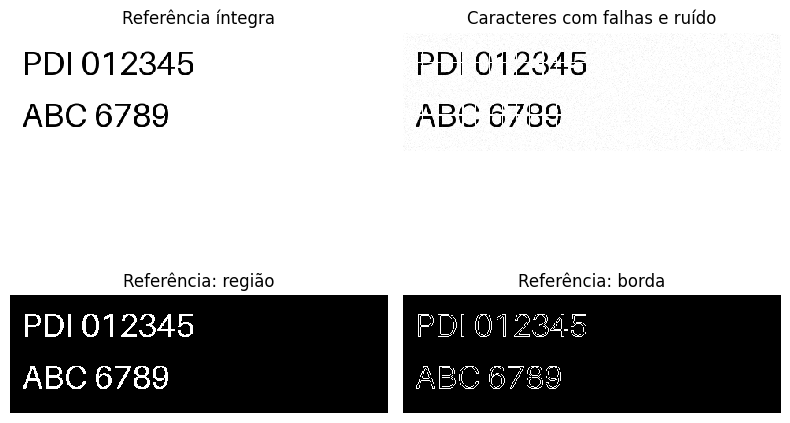

In [14]:
SEMENTE = 42

def exemplo_controlado():
    tela = Image.new('L', (480, 150), 255)

    fonte = None
    for nome in ['DejaVuSans-Bold.ttf', 'Arial.ttf']:
        try:
            fonte = ImageFont.truetype(nome, 42); break
        except OSError: pass
    if fonte is None: fonte = ImageFont.load_default(size=42)
    desenho = ImageDraw.Draw(tela)
    desenho.text((15, 12), 'PDI 012345', fill=0, font=fonte)
    desenho.text((15, 78), 'ABC 6789', fill=0, font=fonte)
    limpa = np.asarray(tela, dtype=float) / 255
    falha = limpa.copy()
    for x in range(24, 455, 17): falha[:, x:x+1+(x%2)] = 1
    falha[37:38, :] = 1; falha[103:105, :] = 1
    rng = np.random.default_rng(SEMENTE)
    degradada = np.clip(falha + rng.normal(0, 0.025, falha.shape), 0, 1)
    return limpa, degradada

def borda_por_diferencas(mask):
    # Borda interna: marca pixel de texto com vizinho ortogonal diferente.
    p = np.pad(mask, 1, constant_values=False)
    centro = p[1:-1, 1:-1]
    return centro & ((centro != p[:-2,1:-1]) | (centro != p[2:,1:-1]) |
                     (centro != p[1:-1,:-2]) | (centro != p[1:-1,2:]))

def metricas_regiao(pred, ref):
    inter = np.count_nonzero(pred & ref)
    uniao = np.count_nonzero(pred | ref)
    soma = pred.sum() + ref.sum()
    return {'IoU': inter/uniao if uniao else 1.0,
            'Dice': 2*inter/soma if soma else 1.0}

def f1_bordas(pred, ref, tolerancia=1.5):
    if not pred.any() or not ref.any():
        return float(np.array_equal(pred, ref))
    precisao = np.mean(distance_transform_edt(~ref)[pred] <= tolerancia)
    revocacao = np.mean(distance_transform_edt(~pred)[ref] <= tolerancia)
    return 2*precisao*revocacao/(precisao+revocacao) if precisao+revocacao else 0.0

limpa, degradada = exemplo_controlado()
ref_texto = limpa < 0.5
ref_borda = borda_por_diferencas(ref_texto)
painel([limpa, degradada, ref_texto, ref_borda],
       ['Referência íntegra', 'Caracteres com falhas e ruído', 'Referência: região', 'Referência: borda'], 2)

### Varredura de parâmetros e comparação com a entrada sem filtro

4. No experimento sintético, utilize a imagem íntegra e sua máscara de texto como referências. Registre também os pixels de texto apagados para produzir as falhas. Avalie:

- PSNR e SSIM: fidelidade das imagens de intensidade em relação à imagem íntegra.
- IoU e Dice: qualidade das máscaras de região produzidas por Otsu e k-means.
- F1 de bordas: qualidade dos contornos. Para comparar os três métodos, extraia as bordas das máscaras de Otsu e k-means e compare-as, junto com Canny, com a mesma borda de referência e a mesma tolerância.

Para avaliar diretamente a redução das falhas, calcule, nas máscaras de Otsu e k-means, a porcentagem dos pixels apagados que voltaram a ser classificados como texto. Compare esse valor antes e depois da filtragem.

Essa porcentagem não deve ser analisada isoladamente: uma máscara excessivamente engrossada pode recuperar os pixels apagados e também classificar o fundo como texto. Apresente falsos positivos e verifique a preservação dos espaços internos e da separação entre caracteres. Na imagem real, sem referência íntegra, apresente uma avaliação visual dos recortes marcados, sem atribuir métricas de acurácia a partir de uma referência desconhecida.

**Dica**: No texto acima, há uma explicação das métricas IoU, Dice e F1.

In [15]:
img_limpa, img_degradada = exemplo_controlado()

# Aplicação dos filtros na imagem degradada

# Frequência de corte = 0.08
img_ideal_08, _, _, _ = filtrar_frequencia(img_degradada, tipo='ideal', fc=0.08)
img_gauss_08, _, _, _ = filtrar_frequencia(img_degradada, tipo='gaussiano', fc=0.08)
img_bw_08_n1, _, _, _ = filtrar_frequencia(img_degradada, tipo='butterworth', fc=0.08, n=1)
img_bw_08_n2, _, _, _ = filtrar_frequencia(img_degradada, tipo='butterworth', fc=0.08, n=2)
img_bw_08_n4, _, _, _ = filtrar_frequencia(img_degradada, tipo='butterworth', fc=0.08, n=4)

# Frequência de corte = 0.16
img_ideal_16, _, _, _ = filtrar_frequencia(img_degradada, tipo='ideal', fc=0.16)
img_gauss_16, _, _, _ = filtrar_frequencia(img_degradada, tipo='gaussiano', fc=0.16)
img_bw_16_n1, _, _, _ = filtrar_frequencia(img_degradada, tipo='butterworth', fc=0.16, n=1)
img_bw_16_n2, _, _, _ = filtrar_frequencia(img_degradada, tipo='butterworth', fc=0.16, n=2)
img_bw_16_n4, _, _, _ = filtrar_frequencia(img_degradada, tipo='butterworth', fc=0.16, n=4)

In [16]:
imagens_avaliar = {
    "Imagem degradada sem filtro": img_degradada,
    "Ideal (fc=0.08)": img_ideal_08,
    "Ideal (fc=0.16)": img_ideal_16,
    "Gaussiano (fc=0.08)": img_gauss_08,
    "Gaussiano (fc=0.16)": img_gauss_16,
    "Butterworth (fc=0.08, n=1)": img_bw_08_n1,
    "Butterworth (fc=0.08, n=2)": img_bw_08_n2,
    "Butterworth (fc=0.08, n=4)": img_bw_08_n4,
    "Butterworth (fc=0.16, n=1)": img_bw_16_n1,
    "Butterworth (fc=0.16, n=2)": img_bw_16_n2,
    "Butterworth (fc=0.16, n=4)": img_bw_16_n4
}

*   PSNR e SSIM

In [17]:

for nome_config, img_teste in imagens_avaliar.items():
    valor_psnr = peak_signal_noise_ratio(img_limpa, img_teste)
    valor_ssim = structural_similarity(img_limpa, img_teste, data_range=1.0) # data_range = valor max possível para o píxel branco

    print(f"{nome_config} -> PSNR: {valor_psnr:.2f} | SSIM: {valor_ssim:.4f}")

Imagem degradada sem filtro -> PSNR: 21.44 | SSIM: 0.8207
Ideal (fc=0.08) -> PSNR: 16.36 | SSIM: 0.7236
Ideal (fc=0.16) -> PSNR: 20.27 | SSIM: 0.8246
Gaussiano (fc=0.08) -> PSNR: 17.87 | SSIM: 0.8800
Gaussiano (fc=0.16) -> PSNR: 20.76 | SSIM: 0.9343
Butterworth (fc=0.08, n=1) -> PSNR: 17.74 | SSIM: 0.8768
Butterworth (fc=0.08, n=2) -> PSNR: 17.17 | SSIM: 0.8515
Butterworth (fc=0.08, n=4) -> PSNR: 16.79 | SSIM: 0.8317
Butterworth (fc=0.16, n=1) -> PSNR: 20.24 | SSIM: 0.9249
Butterworth (fc=0.16, n=2) -> PSNR: 20.47 | SSIM: 0.9285
Butterworth (fc=0.16, n=4) -> PSNR: 20.49 | SSIM: 0.9219


Ao verificar os valores acima, é interessante mantermos a prioridade para a métrica SSIM, pois, para ela atingir uma boa medição, é necessário que o algoritmo consiga remover os ruídos enquanto preserva as bordas e a estrutura dos caracteres. Dado o contexto do trabalho e os valores apresentados, a filtragem Gaussiana com fc = 0.16 foi a que apresentou os melhores resultados, atingindo o maior índice de similaridade estrutural (0.9343) e um excelente PSNR (20.76), garantindo a melhor preservação visual das letras.

*   Otsu, k-means, F1 e Canny

In [18]:
# Parâmetros fixos da questão 3
K_KMEANS = 2
MAX_ITER_KMEANS = 100
SEMENTE_KMEANS = 42

mascaras_otsu = {}
mascaras_kmeans = {}

for nome_config, img_teste in imagens_avaliar.items():

    mascara_o = otsu_threshold(img_teste)
    mascaras_otsu[nome_config] = mascara_o

    mascara_k = kmeans_segmentation(
        img_teste,
        k=K_KMEANS,
        max_iter=MAX_ITER_KMEANS,
        random_state=SEMENTE_KMEANS
    )
    mascaras_kmeans[nome_config] = mascara_k

In [19]:
# Comprovação da explicação do limear 0.5 da próxima célula
valores_continuos = mascaras_kmeans['Imagem degradada sem filtro'][0]
print("Valor Mínimo:", np.min(valores_continuos))
print("Valor Máximo:", np.max(valores_continuos))

Valor Mínimo: 0.06937475388961295
Valor Máximo: 0.9878268389193331


In [20]:
ref_bool = img_limpa < 0.5

ref_borda = borda_por_diferencas(ref_bool)

for nome_config, img_teste in imagens_avaliar.items():
    img_teste = img_teste * 255
    # Otsu
    limiar_otsu = otsu_threshold(img_teste)
    mask_o = img_teste < limiar_otsu
    mascaras_otsu[nome_config] = mask_o

    # k-means
    '''
    O k-means retorna uma matriz com valores contínuos (não binários)
    Se convertido direto para bool, qualquer valor > 0 vira True, gerando um bloco sólido que zera as métricas.
    O limiar '< 0.5' força a binarização correta, marcando apenas os tons escuros como texto (True).
    '''
    mask_k = mascaras_kmeans[nome_config][0] < 0.5
    mascaras_kmeans[nome_config] = mask_k

    metricas_o = metricas_regiao(mask_o, ref_bool)
    metricas_k = metricas_regiao(mask_k, ref_bool)

    borda_o = borda_por_diferencas(mask_o)
    borda_k = borda_por_diferencas(mask_k)
    #Canny
    borda_c = canny(img_teste).astype(bool)

    #F1
    f1_o = f1_bordas(borda_o, ref_borda)
    f1_k = f1_bordas(borda_k, ref_borda)
    f1_c = f1_bordas(borda_c, ref_borda)

    print(f"\n{nome_config}:")
    print(f"Otsu    -> IoU: {metricas_o['IoU']:.4f} | Dice: {metricas_o['Dice']:.4f} | F1 Borda: {f1_o:.4f}")
    print(f"k-means -> IoU: {metricas_k['IoU']:.4f} | Dice: {metricas_k['Dice']:.4f} | F1 Borda: {f1_k:.4f}")
    print(f"Canny   -> F1 Borda: {f1_c:.4f}")


Imagem degradada sem filtro:
Otsu    -> IoU: 0.8437 | Dice: 0.9152 | F1 Borda: 0.9913
k-means -> IoU: 0.8424 | Dice: 0.9145 | F1 Borda: 0.9915
Canny   -> F1 Borda: 0.9993

Ideal (fc=0.08):
Otsu    -> IoU: 0.4322 | Dice: 0.6036 | F1 Borda: 0.2964
k-means -> IoU: 0.0000 | Dice: 0.0000 | F1 Borda: 0.0000
Canny   -> F1 Borda: 0.3248

Ideal (fc=0.16):
Otsu    -> IoU: 0.7070 | Dice: 0.8284 | F1 Borda: 0.9852
k-means -> IoU: 0.7055 | Dice: 0.8273 | F1 Borda: 0.9852
Canny   -> F1 Borda: 0.9269

Gaussiano (fc=0.08):
Otsu    -> IoU: 0.5773 | Dice: 0.7320 | F1 Borda: 0.7648
k-means -> IoU: 0.0000 | Dice: 0.0000 | F1 Borda: 0.0000
Canny   -> F1 Borda: 0.8310

Gaussiano (fc=0.16):
Otsu    -> IoU: 0.7720 | Dice: 0.8713 | F1 Borda: 0.9835
k-means -> IoU: 0.7710 | Dice: 0.8707 | F1 Borda: 0.9832
Canny   -> F1 Borda: 0.9945

Butterworth (fc=0.08, n=1):
Otsu    -> IoU: 0.5890 | Dice: 0.7413 | F1 Borda: 0.7788
k-means -> IoU: 0.0000 | Dice: 0.0000 | F1 Borda: 0.0000
Canny   -> F1 Borda: 0.9636

Butterwo

Após a aplicação dos filtros, entramos na etapa de segmentação utilizando os algoritmos de Otsu e k-means, além do Canny para a extração de bordas. Em seguida, para avaliarmos a recuperação dos pixels, aplicamos as métricas de avaliação: IoU (métrica mais rigorosa, pois verifica a exata área onde a máscara coincide com o gabarito), Dice (também mede a sobreposição, porém dá um peso dobrado aos acertos) e F1-Score (focado em avaliar a qualidade da extração das bordas).

Ao analisarmos os resultados, notamos que a intensidade do filtro afeta diretamente a qualidade da segmentação. A frequência de corte 0.08 borrou excessivamente a imagem, fazendo o k-means falhar completamente e diminuindo o desempenho do Otsu. Embora a imagem sem filtro apresente as maiores métricas isoladas, ela não cumpre o objetivo principal de restaurar as falhas do texto. Portanto, os melhores resultados de restauração foram alcançados com os filtros Gaussiano (fc=0.16) e Butterworth (fc=0.16, n=1) combinados com o método Otsu.



*  Porcentagem dos pixels recuperados



In [21]:
pixels_apagados = (img_limpa < 0.5) & (img_degradada > 0.5)
total_apagados = pixels_apagados.sum()

for nome_config, img_teste in imagens_avaliar.items():
    img_teste = img_teste * 255

    mask_o = mascaras_otsu[nome_config]
    mask_k = mascaras_kmeans[nome_config]

    comparacao_otsu = (pixels_apagados & mask_o).sum()
    comparacao_k = (pixels_apagados & mask_k).sum()

    porcentagem_otsu = (comparacao_otsu / total_apagados) * 100
    porcentagem_k = (comparacao_k / total_apagados) * 100

    print(f"\n{nome_config}:")
    print(f"Otsu:    {porcentagem_otsu:.2f}%")
    print(f"k-means: {porcentagem_k:.2f}%")



Imagem degradada sem filtro:
Otsu:    1.98%
k-means: 2.16%

Ideal (fc=0.08):
Otsu:    91.55%
k-means: 0.00%

Ideal (fc=0.16):
Otsu:    70.50%
k-means: 72.12%

Gaussiano (fc=0.08):
Otsu:    87.41%
k-means: 0.00%

Gaussiano (fc=0.16):
Otsu:    27.34%
k-means: 28.06%

Butterworth (fc=0.08, n=1):
Otsu:    83.63%
k-means: 0.00%

Butterworth (fc=0.08, n=2):
Otsu:    91.73%
k-means: 0.00%

Butterworth (fc=0.08, n=4):
Otsu:    92.09%
k-means: 0.00%

Butterworth (fc=0.16, n=1):
Otsu:    27.16%
k-means: 27.34%

Butterworth (fc=0.16, n=2):
Otsu:    64.39%
k-means: 64.57%

Butterworth (fc=0.16, n=4):
Otsu:    70.14%
k-means: 70.32%


Ao avaliarmos as porcentagens, é fundamental ter cautela para não nos deixarmos enganar pelos resultados com mais de 90% de recuperação. As frequências de corte muito baixas (como fc = 0.08) borram excessivamente a imagem, fazendo com que os tons fiquem muito semelhantes e a tinta se espalhe além dos limites reais do caractere. Esse espalhamento cria o efeito visual de 'letras gordinhas', onde o excesso de tinta não apenas preenche as falhas, mas também invade os espaços que deveriam ser vazios. Isso acaba fundindo as letras e gera uma falsa impressão de sucesso na restauração, já que a alta porcentagem é alcançada às custas da destruição da forma original do texto. Abaixo, apresento as imagens após o borramento, lado a lado com as suas segmentações, para uma comprovação visual:

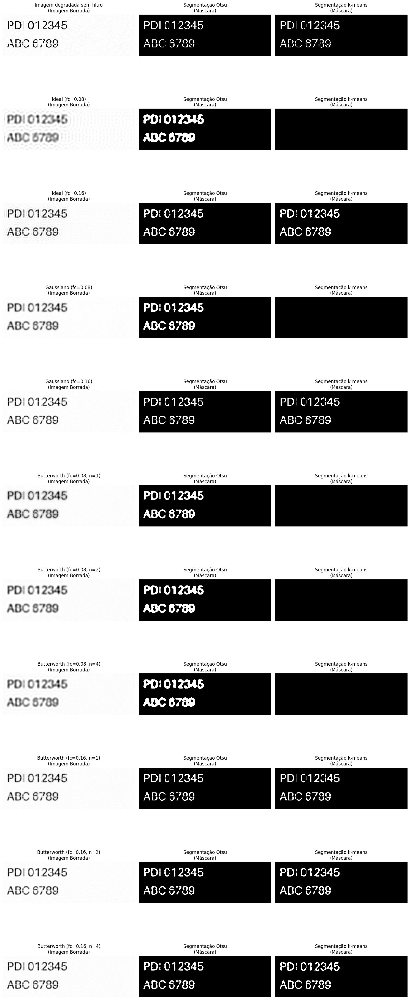

In [22]:
configs = [
    "Imagem degradada sem filtro",
    "Ideal (fc=0.08)",
    "Ideal (fc=0.16)",
    "Gaussiano (fc=0.08)",
    "Gaussiano (fc=0.16)",
    "Butterworth (fc=0.08, n=1)",
    "Butterworth (fc=0.08, n=2)",
    "Butterworth (fc=0.08, n=4)",
    "Butterworth (fc=0.16, n=1)",
    "Butterworth (fc=0.16, n=2)",
    "Butterworth (fc=0.16, n=4)"
]

fig, axes = plt.subplots(nrows=len(configs), ncols=3, figsize=(15, 3.5 * len(configs)))

for i, nome in enumerate(configs):
    img_borrada = imagens_avaliar[nome]
    mask_o = mascaras_otsu[nome]
    mask_k = mascaras_kmeans[nome]

    axes[i, 0].imshow(img_borrada, cmap='gray')
    axes[i, 0].set_title(f"{nome}\n(Imagem Borrada)", fontsize=12)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mask_o, cmap='gray')
    axes[i, 1].set_title("Segmentação Otsu\n(Máscara)", fontsize=12)
    axes[i, 1].axis('off')

    axes[i, 2].imshow(mask_k, cmap='gray')
    axes[i, 2].set_title("Segmentação k-means\n(Máscara)", fontsize=12)
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

Ao analisarmos visualmente as imagens, chegamos a três melhores frequências de corte, sendo respectivamente Ideal (fc = 0.16), Gaussiano (fc = 0.16) e Butterworth (fc = 0.16, n = 1).

Observando a porcentagem de recuperação juntamente com as imagens, verificamos que o motivo de o filtro Ideal ter apresentado um valor muito acima dos demais (~71%) é resultado do efeito de anelamento, gerando ondulações e ecos ao redor dos caracteres. Esse espalhamento ondulado preenche os buracos, inflando a porcentagem, mas insere ruídos estruturais ao redor das letras.

Em contrapartida, os filtros Gaussiano e Butterworth realizam um borramento limpo, sem gerar ondulações. Portanto, a recuperação de ~27% apresentada por eles é estruturalmente mais precisa e confiável.



*   Análise de falsos positivos




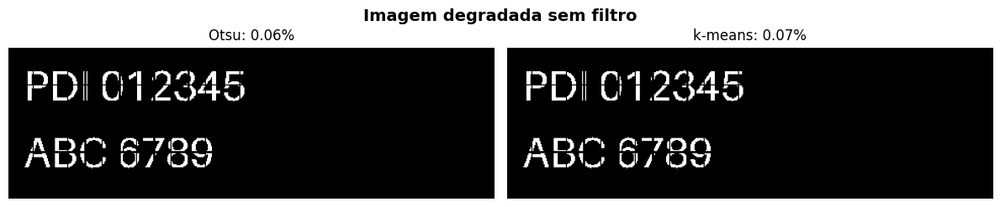

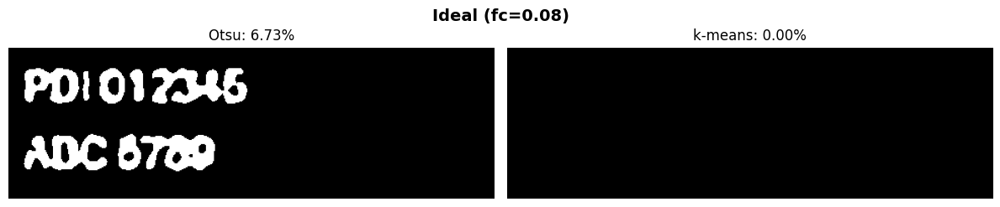

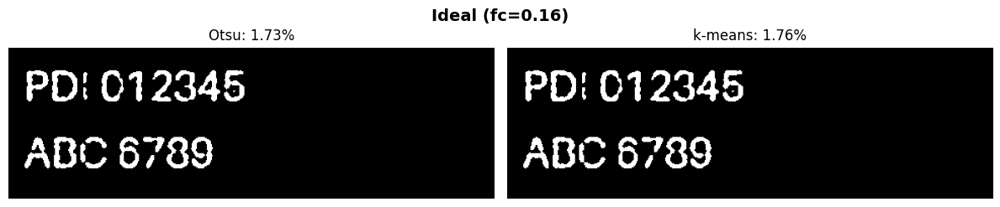

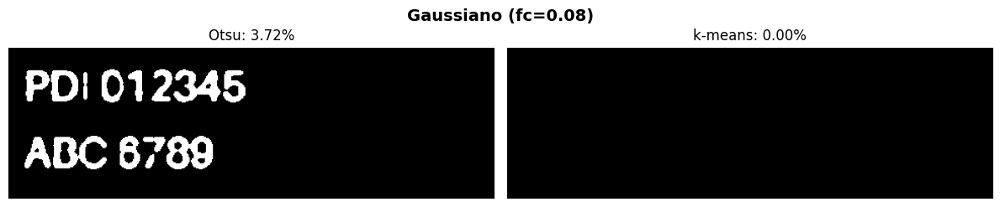

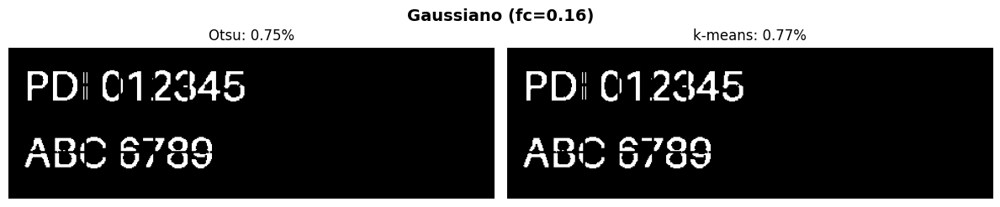

...

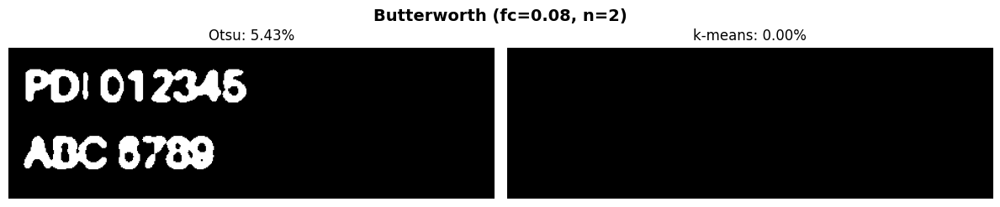

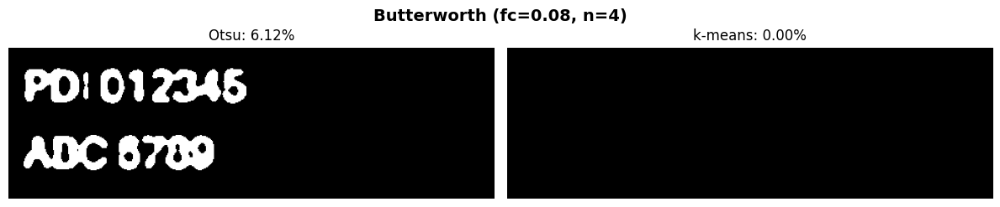

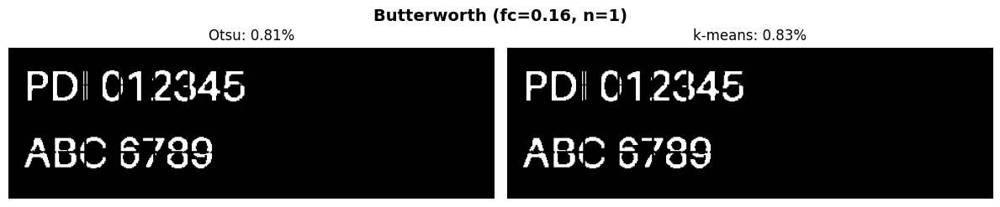

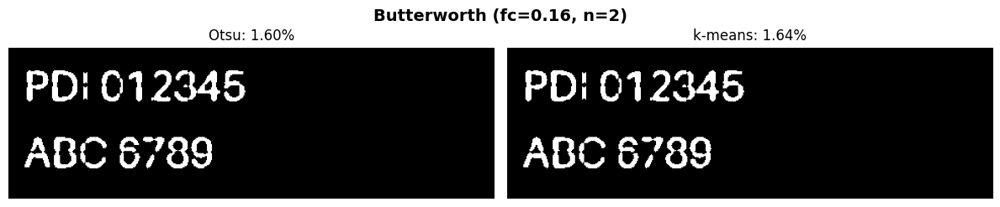

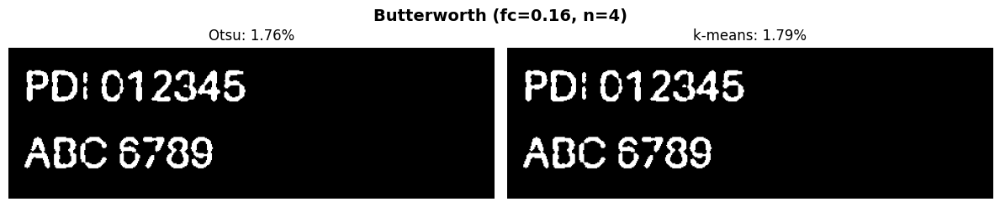

In [23]:
fundo_original = (ref_bool == False).sum()

for nome_config in imagens_avaliar.keys():
    mask_o = mascaras_otsu[nome_config]
    mask_k = mascaras_kmeans[nome_config]

    fp_otsu = ((mask_o == True) & (ref_bool == False)).sum()
    fp_kmeans = ((mask_k == True) & (ref_bool == False)).sum()

    taxa_fp_otsu = (fp_otsu / fundo_original) * 100
    taxa_fp_kmeans = (fp_kmeans / fundo_original) * 100

    fig, axes = plt.subplots(1, 2, figsize=(12, 2.5))
    fig.suptitle(f"{nome_config}", fontsize=14, fontweight='bold')

    axes[0].imshow(mask_o, cmap='gray')
    axes[0].set_title(f"Otsu: {taxa_fp_otsu:.2f}%")
    axes[0].axis('off')

    axes[1].imshow(mask_k, cmap='gray')
    axes[1].set_title(f"k-means: {taxa_fp_kmeans:.2f}%")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

No contexto da segmentação de imagens, um falso positivo ocorre quando o algoritmo se engana e classifica um píxel de fundo como sendo parte do texto. É esse erro que gera o efeito de 'letras gordinhas' comentado anteriormente: o borramento excessivo espalha a cor para áreas que deveriam ser vazias. Teoricamente, ao avaliarmos essa taxa, quanto mais próxima de zero ela for, menor será o erro. Contudo, é fundamental aliar essa métrica à análise visual da imagem. Um algoritmo que falha completamente e gera uma máscara totalmente preta (como ocorreu com o k-means nos filtros de baixa frequência) registrará zero falsos positivos simplesmente porque não detectou nenhuma letra, o que comprova que os números isolados podem ser enganosos sem a devida validação visual.

Avaliando essa métrica, novamente os dois melhores filtros foram o Gaussiano (fc=0.16) e o Butterworth (fc=0.16, n=1). O Gaussiano apresentou apenas 0.75% de falsos positivos no Otsu e 0.77% no k-means. Já o Butterworth registrou 0.81% de falsos positivos no Otsu e 0.83% no k-means. Essas taxas mínimas comprovam que eles conseguiram recuperar as falhas do documento sem invadir o fundo da página, preservando a forma original dos caracteres.



*   Avaliação dos cortes escolhidos



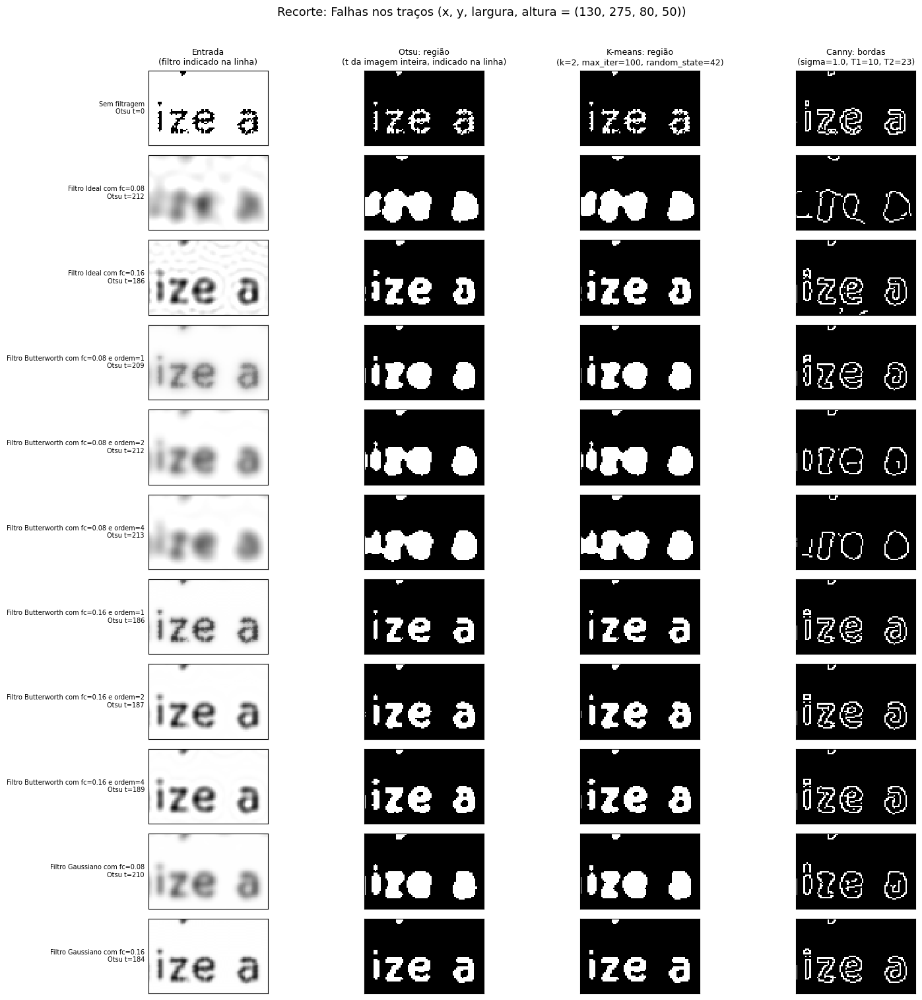

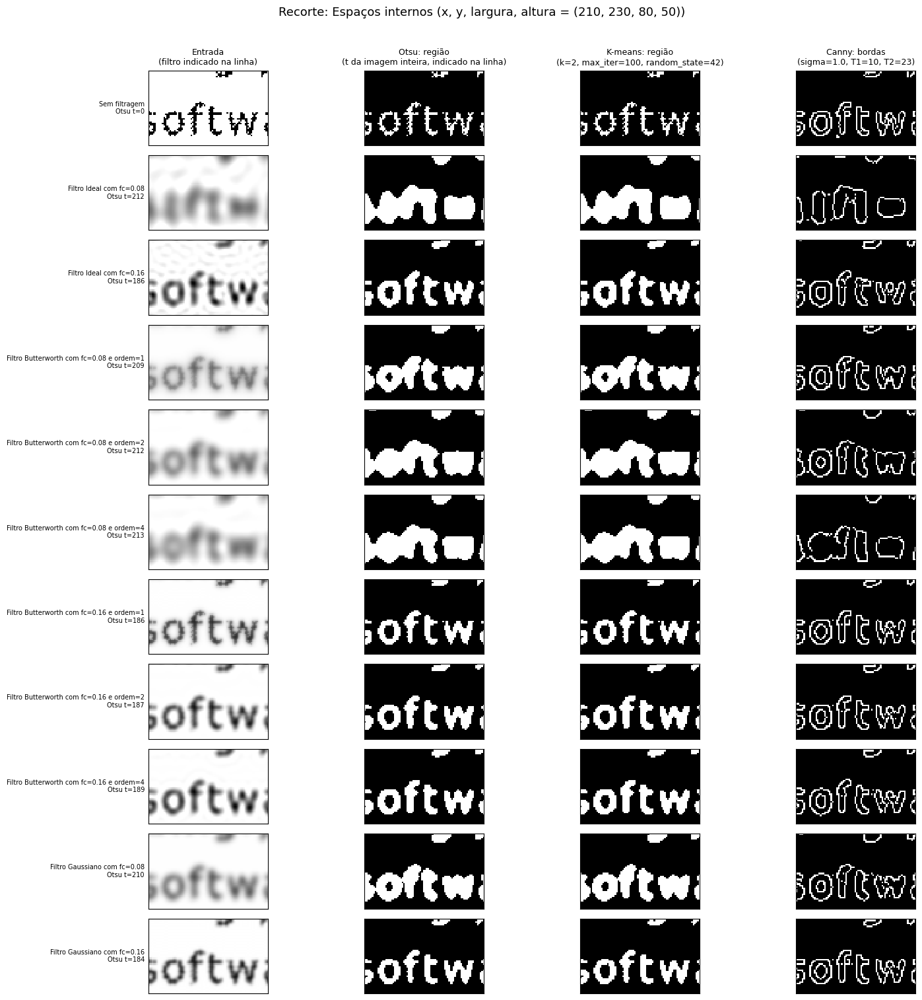

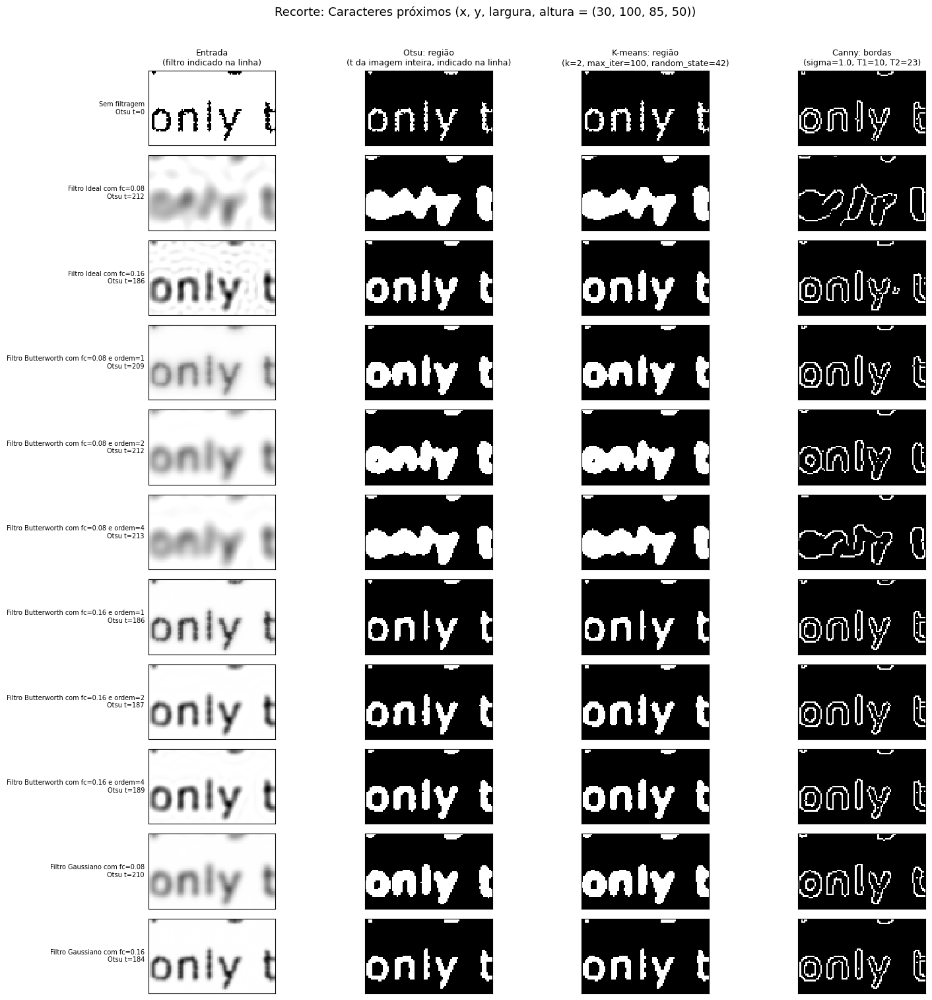

In [24]:
for nome, coords in recortes.items():
    comparar_recorte(nome, coords)

Através da avaliação qualitativa dos recortes, podemos enfatizar que os filtros Gaussiano (fc=0.16) e Butterworth (fc=0.16, n=1) destacaram-se por preservar a espessura e a geometria original da fonte, evitando o excesso de falsos positivos, embora mantenham um aspecto ligeiramente ruidoso e fragmentado nas bordas das letras.

Por outro lado, o filtro Butterworth com ordem mais elevada (fc=0.16, n=4) demonstrou uma capacidade superior de reconstrução. Embora engrosse visivelmente os caracteres, ele preenche as falhas internas de forma muito mais suave e elimina o ruído dos traços, ao mesmo tempo que mantém a distância correta dos caracteres próximos. Ambas as abordagens provaram ser eficazes na restauração da legibilidade do texto real, dependendo se o objetivo prioritário é a fidelidade à espessura original (n=1) ou a solidez do traço reconstruído (n=4).

5. Análise final da filtragem

Para cada segmentador, identifique a configuração de filtragem com o melhor equilíbrio entre redução das falhas e preservação dos caracteres. Compare-a explicitamente com o resultado do mesmo método sem filtragem.

Responda:

- Qual método apresentou o melhor resultado sem filtragem?
- Qual combinação de filtro, parâmetros e segmentador reduziu melhor as falhas?
- A redução das falhas provocou engrossamento de traços, perda de espaços internos ou união de caracteres?
- O melhor resultado de PSNR/SSIM também apresentou a melhor segmentação?
- Em quais situações a filtragem piorou o resultado?
- Sustente as respostas com recortes, parâmetros e métricas. Diferencie a melhor configuração observada neste experimento de uma configuração que funcionaria em outras imagens.

In [25]:
def mostrar_segmentacoes(termo_busca):
    configs_filtradas = [nome for nome in configs if termo_busca in nome]

    fig, axes = plt.subplots(nrows=len(configs_filtradas), ncols=3,
                             figsize=(15, 3.5 * len(configs_filtradas)),
                             squeeze=False)

    for i, nome in enumerate(configs_filtradas):
        img_borrada = imagens_avaliar[nome]
        mask_o = mascaras_otsu[nome]
        mask_k = mascaras_kmeans[nome]

        axes[i, 0].imshow(img_borrada, cmap='gray')
        axes[i, 0].set_title(f"{nome}\n(Imagem Borrada)", fontsize=12)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(mask_o, cmap='gray')
        axes[i, 1].set_title("Segmentação Otsu\n(Máscara)", fontsize=12)
        axes[i, 1].axis('off')

        axes[i, 2].imshow(mask_k, cmap='gray')
        axes[i, 2].set_title("Segmentação k-means\n(Máscara)", fontsize=12)
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

- **Qual método apresentou o melhor resultado sem filtragem?**

  O método de segmentação de região Otsu apresentou a melhor pontuação, registando o maior IoU (0.8437) e Dice (0.9152). Contudo, se o foco for estritamente a preservação das bordas, o método Canny foi superior, alcançando o maior F1 Borda (0.9993).


- **Qual combinação de filtro, parâmetros e segmentador reduziu melhor as falhas?**

  Os melhores resultados de restauração foram alcançados com os filtros Gaussiano (fc=0.16) e Butterworth (fc=0.16, n=1) combinados com o método de segmentação de Otsu. A filtragem Gaussiana destacou-se com o maior SSIM (0.9343) e PSNR (20.76), enquanto a Butterworth apresentou o SSIM de 0.9242 e PSNR de 20.24.

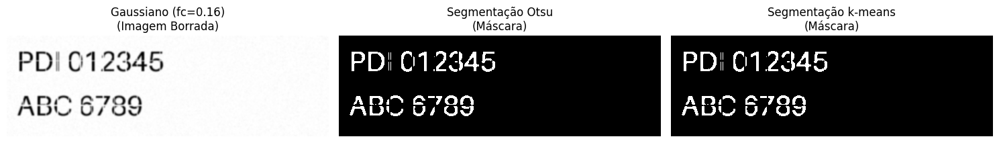

In [26]:
mostrar_segmentacoes("Gaussiano (fc=0.16)")

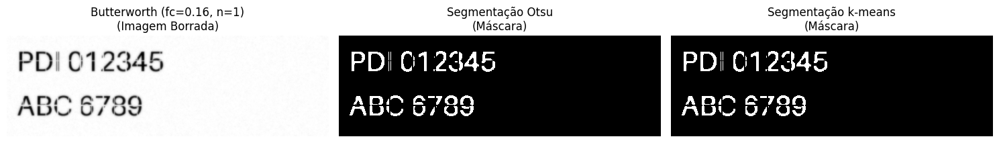

In [27]:
mostrar_segmentacoes("Butterworth (fc=0.16, n=1)")

- **A redução das falhas provocou engrossamento de traços, perda de espaços internos ou união de caracteres?**

  Sim, dependendo da intensidade da filtragem. Os testes que utilizaram frequência de corte 0.08 geraram um excesso de falsos positivos, consequência do borramento excessivo da imagem. Isso causou o engrossamento dos traços, a invasão de espaços internos que deveriam ser vazios e a fusão de caracteres adjacentes, destruindo a forma original do texto.

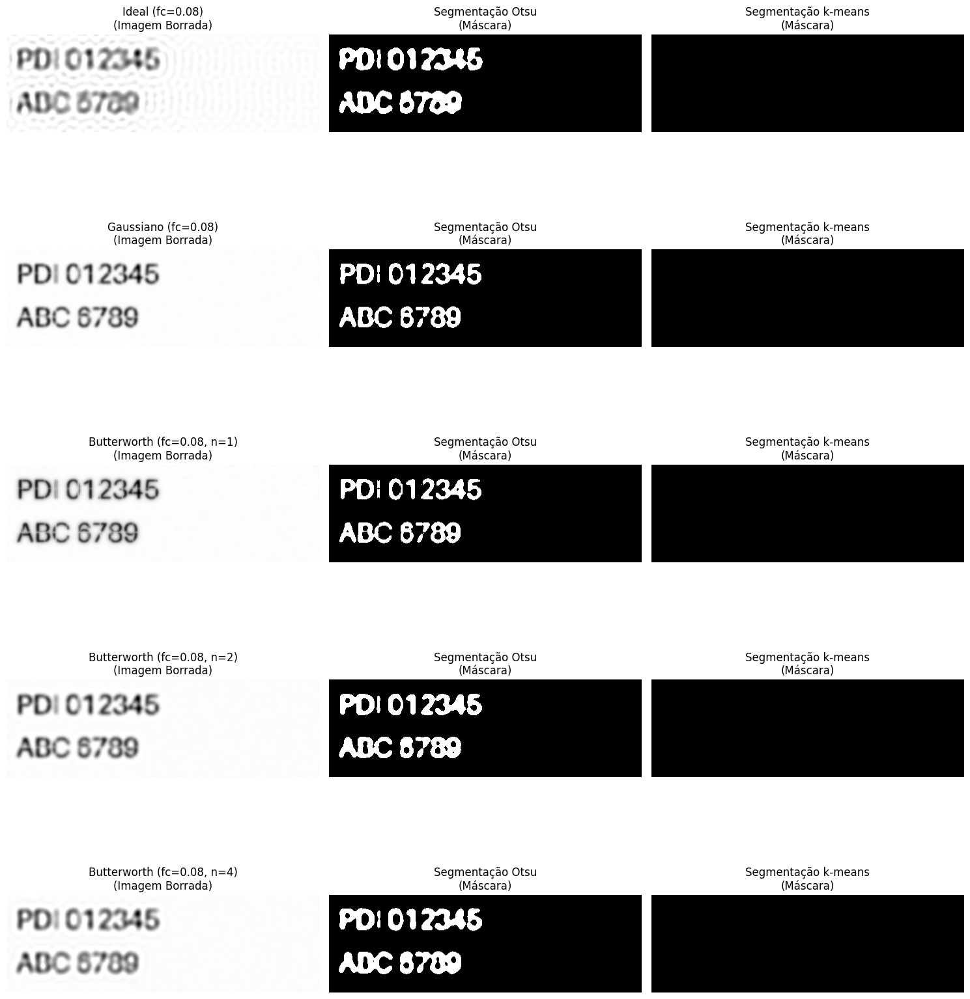

In [28]:
mostrar_segmentacoes("0.08")

- **O melhor resultado de PSNR/SSIM também apresentou a melhor segmentação?**

  Não, mas apresentaram desempenho praticamente idênticos.
  Desconsiderando a imagem original, o filtro Gaussiano (fc=0.16) obteve os maiores índices de qualidade de reconstrução (PSNR de 20.76 e SSIM de 0.9343). No entanto, o pico absoluto de segmentação no método Otsu pertenceu ao Butterworth com fc=0.16 e n=1 (IoU de 0.7725 e Dice de 0.8717).

  | Configuração (fc = 0.16) | PSNR | SSIM | Otsu (IoU) | Otsu (Dice) |
  | :--- | :---: | :---: | :---: | :---: |
  | **Gaussiano** | **20.76** | **0.9343** | 0.7720 | 0.8713 |
  | **Butterworth (n=1)** | 20.24 | 0.9249 | **0.7725** | **0.8717** |

- **Em quais situações a filtragem piorou o resultado?**

  A principal causa de degradação na segmentação foi a frequência de corte restrita (fc = 0.08). O borramento extremo fundiu o texto com o fundo, o que causou a falha total do k-means, que se tornou incapaz de separar as classes e gerou apenas máscaras sólidas.

  Outro fator agravante foi o efeito de anelamento causado pelo corte abrupto do filtro Ideal. A combinação desse fenômeno com a filtragem em 0.08 resultou no pior desempenho de todo o experimento, deformando os caracteres visualmente e registrando as piores métricas do método Otsu (como o IoU de 0.4322). Por fim, a ordem elevada do filtro Butterworth (n=4) também piorou os resultados, pois seu corte muito íngreme imitou as distorções do filtro Ideal em comparação à sua versão mais suave (n=1).

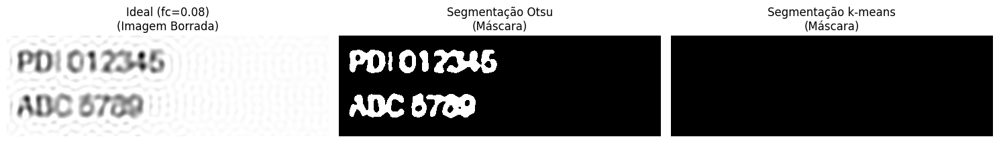

In [29]:
mostrar_segmentacoes("Ideal (fc=0.08)")

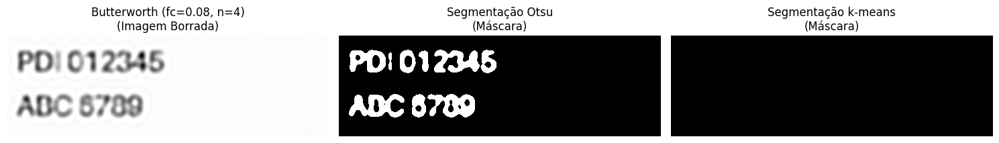

In [30]:
mostrar_segmentacoes("Butterworth (fc=0.08, n=4)")

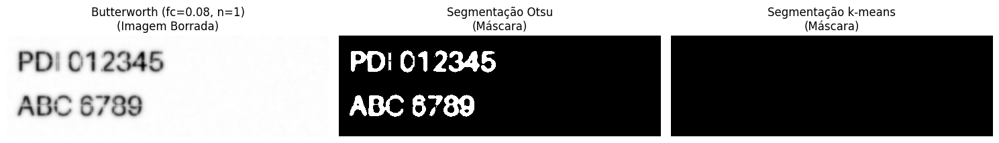

In [31]:
mostrar_segmentacoes("Butterworth (fc=0.08, n=1)")



* **Diferencie a melhor configuração observada neste experimento de uma configuração que funcionaria em outras imagens**

Como concluímos, a melhor configuração foi a filtragem Gaussiana com frequência de corte de 0.16 combinada com a segmentação de Otsu. Não seria possível citar uma configuração universal que funcionasse para outras imagens, pois tudo dependeria dos componentes específicos de cada uma. O fundo é homogêneo ou possui sombras e outros objetos? Como são as cores dessas imagens? Dependendo dessas respostas, uma configuração diferente se aplicaria melhor.

Considerando o filtro Gaussiano, ele funcionou de forma eficaz pois atua separando os componentes da imagem em altas e baixas frequências. As formas grandes e homogêneas da imagem são as "baixas frequências", enquanto os detalhes finos, contornos estreitos e ruídos são as "altas frequências". A frequência de corte de 0.16 funcionou bem porque as letras da imagem são grandes, sendo possível atenuar o ruído e manter a estrutura principal preservada. No entanto, essa mesma configuração poderia falhar e borrar o texto caso as letras fossem menores e mais finas.

Já a segmentação de Otsu funciona bem especificamente para histogramas bimodais. Se a imagem tivesse diferentes cores e iluminações, resultando em um histograma não bimodal, o método falharia. Outro ponto importante a se considerar é o tipo de ruído: o filtro Gaussiano responde bem a determinados tipos (como ruído Gaussiano e de Poisson), mas falha ao tratar outros (como ruídos impulsivos).

Portanto, existem vários fatores que determinam a configuração ideal. Sendo assim, não podemos afirmar que os parâmetros que funcionaram perfeitamente neste cenário de teste seriam úteis ou eficientes para outras imagens.